# Extra — Desafio vaca × cavalo

**FIAP — Fase 6 · seção extra, complementar às Entregas 1 e 2 e ao Ir Além**

No projeto principal as classes são **vaca × trator**. Elas são tão diferentes (animal × máquina, pelo × metal, pasto × lavoura ou estrada) que os modelos praticamente nunca as confundem. Além disso, a sondagem do Ir Além mostrou que um classificador acerta bem acima do acaso vendo **só o fundo** da foto: o pasto verde já entrega a resposta, um atalho que não depende do objeto.

Este extra repete as três frentes do projeto num par mais difícil e mais útil para a FarmTech, **vaca × cavalo**:

* os dois são quadrúpedes grandes, de pelagens parecidas, fotografados nos mesmos pastos — o fundo deixa de distinguir as classes;
* monitorar rebanhos mistos (bovinos e equinos) é um caso real de pecuária, mais próximo do produto do que separar animais de máquinas;
* `cow` e `horse` são **classes nativas do COCO**, então o YOLO pré-treinado vira uma referência justa sem nenhum treino (no par original, `trator` só existia via o atalho `truck/car/bus → trator`).

**Hipótese:** *a dificuldade sobe e o atalho do fundo deixa de funcionar.* Se ela vale, devem aparecer mais erros nos mesmos modelos e protocolos, **trocas de classe vaca ↔ cavalo** como modo de falha novo, e uma acurácia "só fundo" próxima do acaso.

Roteiro (cada parte espelha uma entrega, com o mesmo código, receita e protocolo, para que a comparação com vaca × trator seja direta):

* **A — Entrega 1:** detector YOLOv5s customizado vaca(0)/cavalo(1), mesma receita do `e60` (60 épocas); P, R, mAP, matriz de confusão e casamento de caixas objeto a objeto com **trocas de classe**.
* **B — Entrega 2:** YOLO tradicional (COCO), YOLO customizado e CNN do zero (mesma arquitetura da Entrega 2) nas mesmas imagens; acurácia por imagem com intervalos, McNemar, Grad-CAM e latência no mesmo hardware.
* **C — Ir Além:** MobileNetV2 (transfer + fine tuning) × CNN do zero do Ir Além em validação cruzada 5-fold, e o teste do **atalho do fundo**.
* **D — Lado a lado:** vaca × trator × vaca × cavalo com as mesmas métricas, conclusões geradas a partir dos números e o que isso significa para a FarmTech.

Os números de vaca × trator **não são digitados**: o detector e a CNN da Entrega 2 são reavaliados aqui com o mesmo código (o `best.pt` do `e60` da Entrega 1 é reaproveitado), e os resultados do Ir Além são lidos dos CSVs gravados por aquele notebook (`ir_alem/figuras/`).

## 0. Configuração do ambiente

No **Google Colab**, monta o Drive e usa `MyDrive/fiap_fase6` como pasta do projeto: as vacas vêm de `dataset/` e os cavalos de `extra/dataset_cavalo/`. O YOLOv5 é clonado em `/content/yolov5` no *commit* fixo `f9578796` (o mesmo da Entrega 1), com o `ultralytics` fixado em 8.4.175, porque esse *commit* importa funções internas dele. Localmente, a pasta do projeto é a primeira, subindo a partir da pasta atual, que contém `dataset/`, e o YOLOv5 é o clone já existente em `yolov5/`.

Saídas: figuras e CSVs em `extra/figuras/`; treinos e avaliações do YOLO em `yolov5/runs/extra/`, separados dos treinos `e30`/`e60` do projeto principal. O dataset combinado do YOLO (cópias das 80 imagens e rótulos) fica no disco local da VM no Colab e em `yolov5/runs/extra/` localmente, fora do repositório.

In [1]:
import importlib.metadata
import importlib.util
import os
import shutil
import subprocess
import sys
from pathlib import Path

IN_COLAB = importlib.util.find_spec("google.colab") is not None
DRIVE_PROJECT = Path("/content/drive/MyDrive/fiap_fase6")
COLAB_YOLO_DIR = Path("/content/yolov5")
COLAB_WORK_DIR = Path("/content/extra_vaca_cavalo")
YOLO_REPO = "https://github.com/ultralytics/yolov5"
YOLO_COMMIT = "f9578796b8a64889aa9e66dc06914d19f40d338e"
ULTRALYTICS_VERSION = "8.4.175"


def mount_drive() -> None:
    from google.colab import drive
    drive.mount("/content/drive")


def installed_version(name: str) -> str | None:
    try:
        return importlib.metadata.version(name)
    except importlib.metadata.PackageNotFoundError:
        return None


def pip_install(*args: str) -> None:
    subprocess.run([sys.executable, "-m", "pip", "install", "-q", *args], check=True)


def find_project_dir() -> Path:
    if IN_COLAB:
        return DRIVE_PROJECT
    here = Path.cwd().resolve()
    return next(folder for folder in (here, *here.parents) if (folder / "dataset").is_dir())


def ensure_yolov5(folder: Path) -> None:
    if not folder.exists():
        subprocess.run(["git", "clone", "--quiet", YOLO_REPO, str(folder)], check=True)
        subprocess.run(["git", "-C", str(folder), "checkout", "--quiet", YOLO_COMMIT], check=True)
    if IN_COLAB:
        if installed_version("ultralytics") != ULTRALYTICS_VERSION:
            pip_install(f"ultralytics=={ULTRALYTICS_VERSION}")
        pip_install("-r", str(folder / "requirements.txt"))


if IN_COLAB:
    mount_drive()

PROJECT_DIR = find_project_dir()
YOLO_DIR = COLAB_YOLO_DIR if IN_COLAB else PROJECT_DIR / "yolov5"
ensure_yolov5(YOLO_DIR)

COW_ROOT = PROJECT_DIR / "dataset"
EXTRA_DIR = PROJECT_DIR / "extra"
HORSE_ROOT = EXTRA_DIR / "dataset_cavalo"
FIGURES_DIR = EXTRA_DIR / "figuras"
IR_ALEM_FIGURES = PROJECT_DIR / "ir_alem" / "figuras"
RUNS_DIR = YOLO_DIR / "runs" / "extra"
WORK_DIR = COLAB_WORK_DIR if IN_COLAB else RUNS_DIR

for folder in (FIGURES_DIR, RUNS_DIR, WORK_DIR):
    folder.mkdir(parents=True, exist_ok=True)

print(f"Colab: {IN_COLAB}")
print(f"Projeto: {PROJECT_DIR}")
print(f"Vacas: {COW_ROOT} | Cavalos: {HORSE_ROOT}")
print(f"YOLOv5: {YOLO_DIR} | execuções: {RUNS_DIR}")

Colab: False
Projeto: C:\Users\leelt\fiap-fase6
Vacas: C:\Users\leelt\fiap-fase6\dataset | Cavalos: C:\Users\leelt\fiap-fase6\extra\dataset_cavalo
YOLOv5: C:\Users\leelt\fiap-fase6\yolov5 | execuções: C:\Users\leelt\fiap-fase6\yolov5\runs\extra


### Bibliotecas, dispositivos, constantes e formatação

O TensorFlow é importado **antes** do PyTorch e ativa o *memory growth* em cada GPU; sem isso, no Colab ele reservaria quase toda a VRAM e o YOLOv5 (PyTorch) ficaria sem memória. A célula também define a semente única do experimento, formatadores com vírgula decimal para os textos gerados e as duas funções de figura: gráficos são salvos em PNG; grades de fotos são salvas em PNG (com paleta de 256 cores só quando passariam de 750 KB) e exibidas em JPEG no notebook, o que o mantém leve. As figuras são exibidas com `display`, porque o YOLOv5 troca o *backend* do matplotlib para `Agg` ao ser importado.

In [2]:
os.environ.setdefault("TF_CPP_MIN_LOG_LEVEL", "2")

import contextlib
import io
import logging
import random
import re
import time
import warnings
from collections.abc import Callable
from itertools import combinations
from typing import Any

import tensorflow as tf


def enable_gpu_memory_growth() -> None:
    for gpu in tf.config.list_physical_devices("GPU"):
        try:
            tf.config.experimental.set_memory_growth(gpu, True)
        except RuntimeError as error:
            print(f"Memory growth não ativado em {gpu.name} (GPU já inicializada): {error}")


enable_gpu_memory_growth()

import matplotlib.pyplot as plt
import numpy as np
import pandas as pd
import torch
import yaml
from IPython.display import Image as IPythonImage
from IPython.display import Markdown, display
from matplotlib.lines import Line2D
from matplotlib.patches import Rectangle
from PIL import Image
from scipy.stats import binomtest, fisher_exact
from sklearn.linear_model import LogisticRegression
from sklearn.metrics import ConfusionMatrixDisplay, confusion_matrix
from sklearn.model_selection import StratifiedKFold
from tensorflow import keras
from tensorflow.keras import layers
from tensorflow.keras.applications import mobilenet_v2

warnings.filterwarnings("ignore", category=FutureWarning)
tf.get_logger().setLevel("ERROR")

SEED = 42
CONFIDENCE_LEVEL = 0.95
SIGNIFICANCE = 1 - CONFIDENCE_LEVEL
DECISION_THRESHOLD = 0.5
TF_DEVICE = "GPU" if tf.config.list_physical_devices("GPU") else "CPU"
TORCH_DEVICE = "cuda" if torch.cuda.is_available() else "cpu"
YOLO_DEVICE = "0" if torch.cuda.is_available() else "cpu"

CHART_DPI = 110
PHOTO_DPI = 80
JPEG_QUALITY = 85
PALETTE_COLORS = 256
MAX_PNG_BYTES = 750 * 1024
CREDITS_CAPTION = "Imagens: Wikimedia Commons; créditos em dataset/CREDITS.md e extra/dataset_cavalo/CREDITS.md"


def fmt_num(value: float, digits: int = 3, signed: bool = False) -> str:
    return f"{value:{'+' if signed else ''}.{digits}f}".replace(".", ",")


def fmt_pct(value: float, digits: int = 1) -> str:
    return f"{fmt_num(100 * value, digits)}%"


def fmt_p(value: float) -> str:
    return "p < 0,001" if value < 0.001 else f"p = {fmt_num(value, 3)}"


def fmt_interval(low: float, high: float, digits: int = 2) -> str:
    return f"[{fmt_num(low, digits)}; {fmt_num(high, digits)}]"


def plural(count: int, singular: str, plural_form: str) -> str:
    return f"{count} {singular if count == 1 else plural_form}"


def show_markdown(lines: list[str], title: str = "") -> None:
    heading = [f"#### {title}"] if title else []
    display(Markdown("\n".join([*heading, *(f"- {line}" for line in lines)])))


def set_seeds(seed: int = SEED) -> None:
    random.seed(seed)
    np.random.seed(seed)
    torch.manual_seed(seed)
    keras.utils.set_random_seed(seed)


def report_size(path: Path) -> None:
    print(f"Figura salva em {path.relative_to(PROJECT_DIR).as_posix()} ({fmt_num(path.stat().st_size / 1024, 0)} KB)")


def save_chart(fig: plt.Figure, name: str) -> None:
    path = FIGURES_DIR / name
    fig.savefig(path, dpi=CHART_DPI, bbox_inches="tight")
    report_size(path)
    display(fig)
    plt.close(fig)


def save_png_under_limit(fig: plt.Figure, path: Path, dpi: int) -> None:
    rendered = io.BytesIO()
    fig.savefig(rendered, format="png", dpi=dpi, bbox_inches="tight")
    image = Image.open(rendered).convert("RGB")
    image.save(path, optimize=True)
    if path.stat().st_size > MAX_PNG_BYTES:
        image.quantize(PALETTE_COLORS, method=Image.Quantize.FASTOCTREE).save(path, optimize=True)


def save_photo_grid(fig: plt.Figure, name: str, dpi: int = PHOTO_DPI) -> None:
    path = FIGURES_DIR / name
    save_png_under_limit(fig, path, dpi)
    buffer = io.BytesIO()
    fig.savefig(buffer, format="jpeg", dpi=dpi, bbox_inches="tight", pil_kwargs={"quality": JPEG_QUALITY})
    plt.close(fig)
    report_size(path)
    display(IPythonImage(data=buffer.getvalue(), format="jpeg"))


set_seeds()
print(f"TensorFlow {tf.__version__} em {TF_DEVICE} | PyTorch {torch.__version__} em {TORCH_DEVICE}"
      + (f" ({torch.cuda.get_device_name(0)})" if torch.cuda.is_available() else ""))

TensorFlow 2.19.0 em CPU | PyTorch 2.14.1+cu126 em cuda (NVIDIA GeForce RTX 4070 Laptop GPU)


### 0.1 Os dois pares e a conferência dos rótulos

Cada par é descrito pelas suas classes (índice 0 e 1, na ordem do rótulo YOLO) e pela pasta de onde vem cada classe. As **vacas são as mesmas 40 imagens nos dois pares** (mesmos splits e caixas), então qualquer diferença entre os pares vem da segunda classe. A classe de cada imagem sai do prefixo do nome (`vaca_NNN.jpg`, `cavalo_NNN.jpg`, `trator_NNN.jpg`) e as caixas, dos `.txt` no formato YOLO.

A célula para com a lista de problemas se alguma imagem não tiver rótulo, tiver uma linha inválida ou se algum split não tiver as duas classes. A tabela conta **imagens e caixas** por split e classe: as métricas de detecção contam caixas.

In [3]:
PAIR_OLD, PAIR_NEW = "vaca × trator", "vaca × cavalo"
PAIR_COLORS = {PAIR_OLD: "#2a78d6", PAIR_NEW: "#eb6834"}
PAIRS = {
    PAIR_OLD: {"classes": ("vaca", "trator"), "roots": {"vaca": COW_ROOT, "trator": COW_ROOT}},
    PAIR_NEW: {"classes": ("vaca", "cavalo"), "roots": {"vaca": COW_ROOT, "cavalo": HORSE_ROOT}},
}
SPLITS = ("train", "val", "test")
TEST_SET, VAL_TEST_SET = "teste", "val+teste"
IMAGE_SUFFIX = ".jpg"
LABEL_FIELDS = 5
Truth = tuple[str, list[float]]
Detection = tuple[str, float, list[float]]


def classes_of(pair: str) -> tuple[str, str]:
    return PAIRS[pair]["classes"]


def class_from_name(path: Path) -> str:
    return path.stem.rsplit("_", 1)[0]


def pair_paths(pair: str, split: str) -> list[Path]:
    found = [path for name, root in PAIRS[pair]["roots"].items()
             for path in (root / "images" / split).glob(f"{name}_*{IMAGE_SUFFIX}")]
    return sorted(found, key=lambda path: path.name)


def label_file(path: Path) -> Path:
    return path.parents[2] / "labels" / path.parent.name / f"{path.stem}.txt"


def read_rows(path: Path) -> list[list[float]]:
    file = label_file(path)
    lines = file.read_text(encoding="utf-8").splitlines() if file.exists() else []
    return [[float(field) for field in line.split()] for line in lines if line.strip()]


def is_valid_row(row: list[float]) -> bool:
    return len(row) == LABEL_FIELDS and int(row[0]) in (0, 1) and all(0 <= value <= 1 for value in row[1:])


def to_pixels(row: list[float], width: int, height: int) -> list[float]:
    _, x_center, y_center, box_width, box_height = row
    return [(x_center - box_width / 2) * width, (y_center - box_height / 2) * height,
            (x_center + box_width / 2) * width, (y_center + box_height / 2) * height]


def read_truths(pair: str, path: Path) -> list[Truth]:
    width, height = Image.open(path).size
    return [(classes_of(pair)[int(row[0])], to_pixels(row, width, height)) for row in read_rows(path)]


def image_problems(path: Path) -> list[str]:
    where = f"{path.parent.name}/{path.name}"
    if not label_file(path).exists():
        return [f"{where}: sem arquivo de rótulo"]
    rows = read_rows(path)
    if not rows:
        return [f"{where}: nenhuma caixa"]
    return [f"{where}: linha inválida {row}" for row in rows if not is_valid_row(row)]


def pair_problems(pair: str) -> list[str]:
    problems = [problem for split in SPLITS for path in PATHS[pair][split] for problem in image_problems(path)]
    for split in SPLITS:
        present = {class_from_name(path) for path in PATHS[pair][split]}
        problems += [f"{pair}/{split}: nenhuma imagem de {name}" for name in classes_of(pair) if name not in present]
    return problems


def inventory_row(pair: str, split: str) -> dict[str, Any]:
    paths = PATHS[pair][split]
    boxes = [label for path in paths for label, _ in TRUTHS[pair][path.name]]
    images = [class_from_name(path) for path in paths]
    return {"par": pair, "split": split,
            **{f"imagens {position}": images.count(name) for position, name in zip(("classe 0", "classe 1"), classes_of(pair))},
            **{f"caixas {position}": boxes.count(name) for position, name in zip(("classe 0", "classe 1"), classes_of(pair))},
            "classes": " / ".join(classes_of(pair))}


PATHS = {pair: {split: pair_paths(pair, split) for split in SPLITS} for pair in PAIRS}
PROBLEMS = [problem for pair in PAIRS for problem in pair_problems(pair)]
if PROBLEMS:
    raise ValueError("Problemas no dataset:\n" + "\n".join(PROBLEMS))
PATH_INDEX = {pair: {path.name: path for split in SPLITS for path in PATHS[pair][split]} for pair in PAIRS}
TRUTHS = {pair: {name: read_truths(pair, path) for name, path in PATH_INDEX[pair].items()} for pair in PAIRS}
EVAL_PATHS = {pair: {TEST_SET: PATHS[pair]["test"], VAL_TEST_SET: PATHS[pair]["val"] + PATHS[pair]["test"]} for pair in PAIRS}
Y_TRUE = {pair: {set_name: [class_from_name(path) for path in paths] for set_name, paths in sets.items()}
          for pair, sets in EVAL_PATHS.items()}
INVENTORY = pd.DataFrame([inventory_row(pair, split) for pair in PAIRS for split in SPLITS]).set_index(["par", "split"])
INVENTORY

imagens classe 0  imagens classe 1  caixas classe 0  \
par           split                                                        
vaca × trator train                32                32               95   
              val                   4                 4               16   
              test                  4                 4               11   
vaca × cavalo train                32                32               95   
              val                   4                 4               16   
              test                  4                 4               11   

                     caixas classe 1        classes  
par           split                                  
vaca × trator train               37  vaca / trator  
              val                  4  vaca / trator  
              test                 5  vaca / trator  
vaca × cavalo train               79  vaca / cavalo  
              val                  6  vaca / cavalo  
              test                 9  vaca / cavalo

### 0.2 Amostras

Quatro vacas e quatro cavalos do treino, escolhidos em intervalos regulares da lista ordenada (sem escolha manual). As fotos mostram o que torna o par difícil: animais de porte e pelagem parecidos, no mesmo tipo de pasto.

Figura salva em extra/figuras/amostras.png (519 KB)


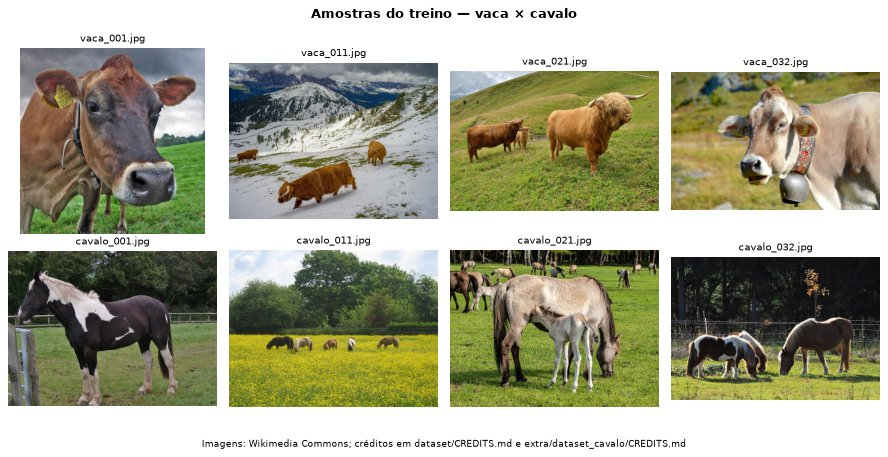

In [4]:
SAMPLES_PER_CLASS = 4
SAMPLE_CELL = 2.8


def evenly_spaced(paths: list[Path], count: int) -> list[Path]:
    return [paths[index] for index in np.linspace(0, len(paths) - 1, count).astype(int)]


def plot_samples(pair: str, name: str) -> None:
    classes = classes_of(pair)
    fig, axes = plt.subplots(len(classes), SAMPLES_PER_CLASS, figsize=(SAMPLE_CELL * SAMPLES_PER_CLASS, SAMPLE_CELL * len(classes)))
    for row, label in zip(axes, classes):
        paths = evenly_spaced([path for path in PATHS[pair]["train"] if class_from_name(path) == label], SAMPLES_PER_CLASS)
        for ax, path in zip(row, paths):
            ax.imshow(Image.open(path))
            ax.set_title(path.name, fontsize=9)
            ax.axis("off")
    fig.suptitle(f"Amostras do treino — {pair}", fontweight="bold")
    fig.text(0.5, 0, CREDITS_CAPTION, ha="center", fontsize=8)
    fig.tight_layout(rect=(0, 0.03, 1, 1))
    save_photo_grid(fig, name)


plot_samples(PAIR_NEW, "amostras.png")

---
## A. Espelho da Entrega 1 — detector YOLOv5 customizado vaca × cavalo

### A.1 Dataset combinado e arquivos YAML

O YOLOv5 espera uma única raiz com `images/{split}` e `labels/{split}`. Como as vacas e os cavalos vivem em pastas diferentes, copiamos as 80 imagens e seus rótulos para uma pasta de trabalho (recriada a cada execução). Os rótulos de vaca já usam a classe 0 e os de cavalo, a classe 1, então a cópia é direta. O YAML de vaca × trator aponta para o `dataset/` do projeto, exatamente como o da Entrega 1.

In [5]:
YOLO_DATA_DIR = WORK_DIR / "dados_vaca_cavalo"
DATA_ROOTS = {PAIR_OLD: COW_ROOT, PAIR_NEW: YOLO_DATA_DIR}
DATA_YAMLS = {PAIR_OLD: RUNS_DIR / "vaca_trator.yaml", PAIR_NEW: RUNS_DIR / "vaca_cavalo.yaml"}


def build_yolo_dataset(pair: str, target: Path) -> None:
    shutil.rmtree(target, ignore_errors=True)
    for split in SPLITS:
        for kind in ("images", "labels"):
            (target / kind / split).mkdir(parents=True)
        for path in PATHS[pair][split]:
            shutil.copy2(path, target / "images" / split / path.name)
            shutil.copy2(label_file(path), target / "labels" / split / f"{path.stem}.txt")


def write_data_yaml(pair: str) -> None:
    config = {"path": DATA_ROOTS[pair].as_posix(), **{split: f"images/{split}" for split in SPLITS},
              "nc": len(classes_of(pair)), "names": list(classes_of(pair))}
    DATA_YAMLS[pair].write_text(yaml.safe_dump(config, allow_unicode=True, sort_keys=False), encoding="utf-8")


build_yolo_dataset(PAIR_NEW, YOLO_DATA_DIR)
for pair in PAIRS:
    write_data_yaml(pair)
print(DATA_YAMLS[PAIR_NEW].read_text(encoding="utf-8"))

path: C:/Users/leelt/fiap-fase6/yolov5/runs/extra/dados_vaca_cavalo
train: images/train
val: images/val
test: images/test
nc: 2
names:
- vaca
- cavalo



### A.2 Treinamento com a receita do `e60`

Mesma receita do modelo escolhido na Entrega 1: `yolov5s.pt` pré-treinado no COCO, imagem 640, *batch* 16, semente 42, **60 épocas** e hiperparâmetros padrão (`hyp.scratch-low.yaml`). `run_yolo` chama os scripts do YOLOv5 com o mesmo Python do notebook e mostra só o fim do log; o tempo do laço de épocas é lido do próprio log.

Para vaca × trator reaproveitamos o `best.pt` do `e60` da Entrega 1 (em `yolov5/runs/train/e60` ou, no Colab, na cópia persistida em `resultados_yolo/`). Se ele não existir, o notebook treina o mesmo modelo aqui, com a mesma receita, em `runs/extra/train/vaca_trator_e60`.

In [6]:
IMG_SIZE = 640
BATCH = 16
EPOCHS = 60
WORKERS = 2
BASE_WEIGHTS = "yolov5s.pt"
LOG_TAIL = 6
CHILD_ENV = {**os.environ, "PYTHONIOENCODING": "utf-8"}
ANSI_PATTERN = re.compile(r"\x1b\[[0-9;]*[A-Za-z]")
PROGRESS_PATTERN = re.compile(r"\d+%\s*[━─█|]")
EPOCH_LOOP_PATTERN = re.compile(r"epochs completed in ([\d.]+) hours")
SECONDS_PER_HOUR = 3600
RUN_NAMES = {PAIR_OLD: "vaca_trator_e60", PAIR_NEW: "vaca_cavalo_e60"}
MAIN_RUN_CANDIDATES = (YOLO_DIR / "runs" / "train" / "e60", PROJECT_DIR / "resultados_yolo" / "train" / "e60")
TRAIN_TIMES: dict[str, dict[str, float]] = {}


def run_yolo(script: str, *args: object) -> str:
    result = subprocess.run([sys.executable, script, *map(str, args)], cwd=YOLO_DIR, env=CHILD_ENV, text=True,
                            encoding="utf-8", errors="replace", stdout=subprocess.PIPE, stderr=subprocess.STDOUT)
    log = ANSI_PATTERN.sub("", result.stdout)
    print("\n".join([line for line in log.splitlines() if not PROGRESS_PATTERN.search(line)][-LOG_TAIL:]))
    result.check_returncode()
    return log


def train_yolo(pair: str) -> Path:
    run_dir = RUNS_DIR / "train" / RUN_NAMES[pair]
    shutil.rmtree(run_dir, ignore_errors=True)
    start = time.perf_counter()
    log = run_yolo("train.py", "--img", IMG_SIZE, "--batch", BATCH, "--epochs", EPOCHS, "--data", DATA_YAMLS[pair],
                   "--weights", BASE_WEIGHTS, "--seed", SEED, "--workers", WORKERS, "--device", YOLO_DEVICE,
                   "--project", RUNS_DIR / "train", "--name", RUN_NAMES[pair], "--exist-ok")
    loop_seconds = float(EPOCH_LOOP_PATTERN.findall(log)[-1]) * SECONDS_PER_HOUR
    TRAIN_TIMES[pair] = {"total_s": time.perf_counter() - start, "epoch_loop_s": loop_seconds}
    print(f"{pair}: {fmt_num(TRAIN_TIMES[pair]['total_s'], 0)} s no total, {fmt_num(loop_seconds, 0)} s no laço de épocas")
    return run_dir


def main_run_dir() -> Path | None:
    return next((folder for folder in MAIN_RUN_CANDIDATES if (folder / "weights" / "best.pt").exists()), None)


YOLO_RUN_DIRS = {PAIR_NEW: train_yolo(PAIR_NEW)}
YOLO_RUN_DIRS[PAIR_OLD] = main_run_dir() or train_yolo(PAIR_OLD)
CUSTOM_WEIGHTS = {pair: folder / "weights" / "best.pt" for pair, folder in YOLO_RUN_DIRS.items()}
for pair, weights in CUSTOM_WEIGHTS.items():
    print(f"{pair}: {weights}")

Model summary: 68 layers, 7,015,519 parameters, 0 gradients

                   all          8         22      0.869      0.629      0.694       0.55
                  vaca          8         16      0.772      0.426      0.552      0.361
                cavalo          8          6      0.966      0.833      0.836       0.74
Results saved to C:\Users\leelt\fiap-fase6\yolov5\runs\extra\train\vaca_cavalo_e60
vaca × cavalo: 162 s no total, 90 s no laço de épocas
vaca × cavalo: C:\Users\leelt\fiap-fase6\yolov5\runs\extra\train\vaca_cavalo_e60\weights\best.pt
vaca × trator: C:\Users\leelt\fiap-fase6\yolov5\runs\train\e60\weights\best.pt


### A.3 Curvas de treino lado a lado

Cada treino grava `results.csv` com uma linha por época. Sobrepomos os dois pares em quatro painéis: mAP50-95, precisão e revocação de validação, e a *loss* de **classificação** de validação (`val/cls_loss`). É nessa *loss* que a dificuldade do par deve aparecer primeiro: localizar um quadrúpede é igualmente fácil nos dois casos, mas dizer se ele é vaca ou cavalo exige detalhes finos.

Figura salva em extra/figuras/curvas_yolo.png (127 KB)


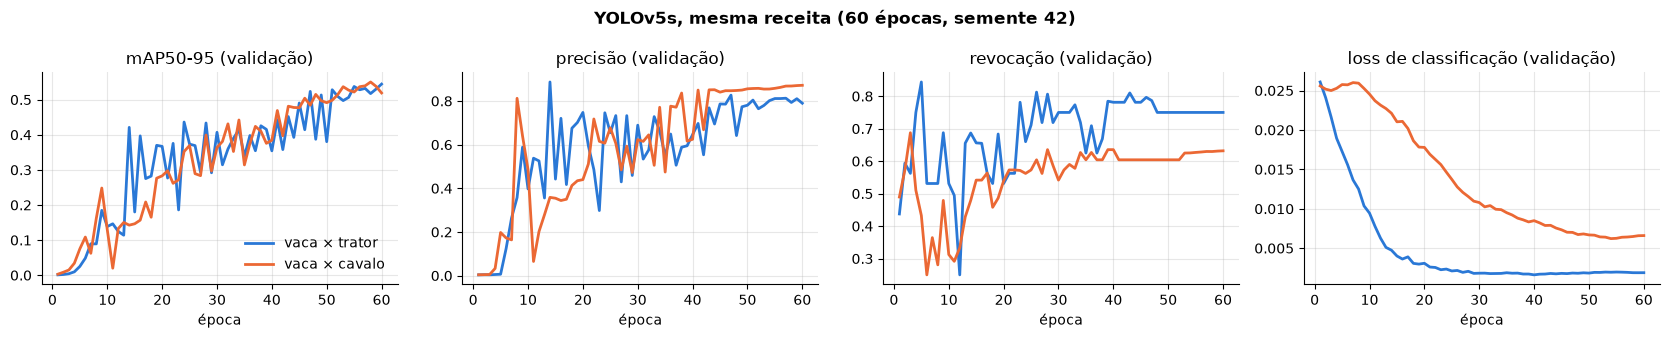

In [7]:
CURVE_PANELS = {"metrics/mAP_0.5:0.95": "mAP50-95 (validação)", "metrics/precision": "precisão (validação)",
                "metrics/recall": "revocação (validação)", "val/cls_loss": "loss de classificação (validação)"}


def load_history(pair: str) -> pd.DataFrame:
    history = pd.read_csv(YOLO_RUN_DIRS[pair] / "results.csv")
    history.columns = history.columns.str.strip()
    return history


def plot_yolo_curves(name: str) -> None:
    fig, axes = plt.subplots(1, len(CURVE_PANELS), figsize=(4.2 * len(CURVE_PANELS), 3.4))
    for ax, (column, title) in zip(axes, CURVE_PANELS.items()):
        for pair, history in YOLO_HISTORY.items():
            ax.plot(history["epoch"] + 1, history[column], color=PAIR_COLORS[pair], linewidth=2, label=pair)
        ax.set(title=title, xlabel="época")
        ax.grid(alpha=0.3)
        ax.spines[["top", "right"]].set_visible(False)
    axes[0].legend(frameon=False)
    fig.suptitle(f"YOLOv5s, mesma receita ({EPOCHS} épocas, semente {SEED})", fontweight="bold")
    fig.tight_layout()
    save_chart(fig, name)


YOLO_HISTORY = {pair: load_history(pair) for pair in PAIRS}
plot_yolo_curves("curvas_yolo.png")

### A.4 Validação e teste com o `val.py`

O `quiet_yolo` silencia o *logger* do YOLOv5 e, ao sair, restaura o estilo padrão do matplotlib, que o `val.py` troca pelo tema do seaborn ao desenhar a matriz de confusão. Avaliamos o `best.pt` de cada par em validação e teste com `val.run` do YOLOv5, com *batch* 1 (o mesmo protocolo da seção 4.1 da Entrega 1, o que reproduz os números de vaca × trator de lá). O teste nunca participou do treino nem da escolha do `best.pt`. Além de P, R, mAP50 e mAP50-95, guardamos o mAP50-95 de cada classe: a vaca é a mesma nos dois pares, então uma queda nela mostra que a dificuldade nova contamina também a classe antiga.

In [8]:
EVAL_BATCH = 1
YOLO_SPLITS = {"val": "val", "test": TEST_SET}
YOLO_METRIC_NAMES = ["P", "R", "mAP50", "mAP50-95"]

if str(YOLO_DIR) not in sys.path:
    sys.path.insert(0, str(YOLO_DIR))
import val as yolo_val
from utils.general import LOGGER as YOLO_LOGGER


@contextlib.contextmanager
def quiet_yolo():
    level = YOLO_LOGGER.level
    YOLO_LOGGER.setLevel(logging.ERROR)
    try:
        with contextlib.redirect_stdout(io.StringIO()), contextlib.redirect_stderr(io.StringIO()):
            yield
    finally:
        YOLO_LOGGER.setLevel(level)
        plt.rcdefaults()


def evaluate_yolo_split(pair: str, task: str) -> dict[str, Any]:
    with quiet_yolo():
        (precision, recall, map50, map50_95, *_), per_class, speed = yolo_val.run(
            data=DATA_YAMLS[pair], weights=CUSTOM_WEIGHTS[pair], batch_size=EVAL_BATCH, imgsz=IMG_SIZE, task=task,
            device=YOLO_DEVICE, workers=0, project=RUNS_DIR / "val", name=f"{RUN_NAMES[pair]}_{task}", exist_ok=True)
    first, second = classes_of(pair)
    return {"par": pair, "split": YOLO_SPLITS[task], "P": precision, "R": recall, "mAP50": map50, "mAP50-95": map50_95,
            "mAP50-95 vaca": per_class[0], "mAP50-95 2ª classe": per_class[1], "2ª classe": second,
            "inferência val.py (ms/img)": speed[1]}


YOLO_METRICS = pd.DataFrame([evaluate_yolo_split(pair, task) for pair in PAIRS for task in YOLO_SPLITS]).set_index(["par", "split"])
YOLO_METRICS.to_csv(FIGURES_DIR / "yolo_metricas.csv")
YOLO_METRICS.style.format(precision=3, decimal=",", subset=YOLO_METRIC_NAMES + ["mAP50-95 vaca", "mAP50-95 2ª classe"])

### A.5 Matriz de confusão do YOLOv5 (teste)

A matriz gravada pelo `val.py`: colunas são a classe real e linhas a prevista, normalizadas por coluna. A linha `background` mostra objetos **não detectados** e a coluna `background`, **alarmes falsos**. O que interessa aqui é o quadrante fora da diagonal entre as duas classes: é ali que aparece a **troca de classe**, que no par vaca × trator a Entrega 1 nunca observou.

Figura salva em extra/figuras/matriz_confusao_yolo.png (47 KB)


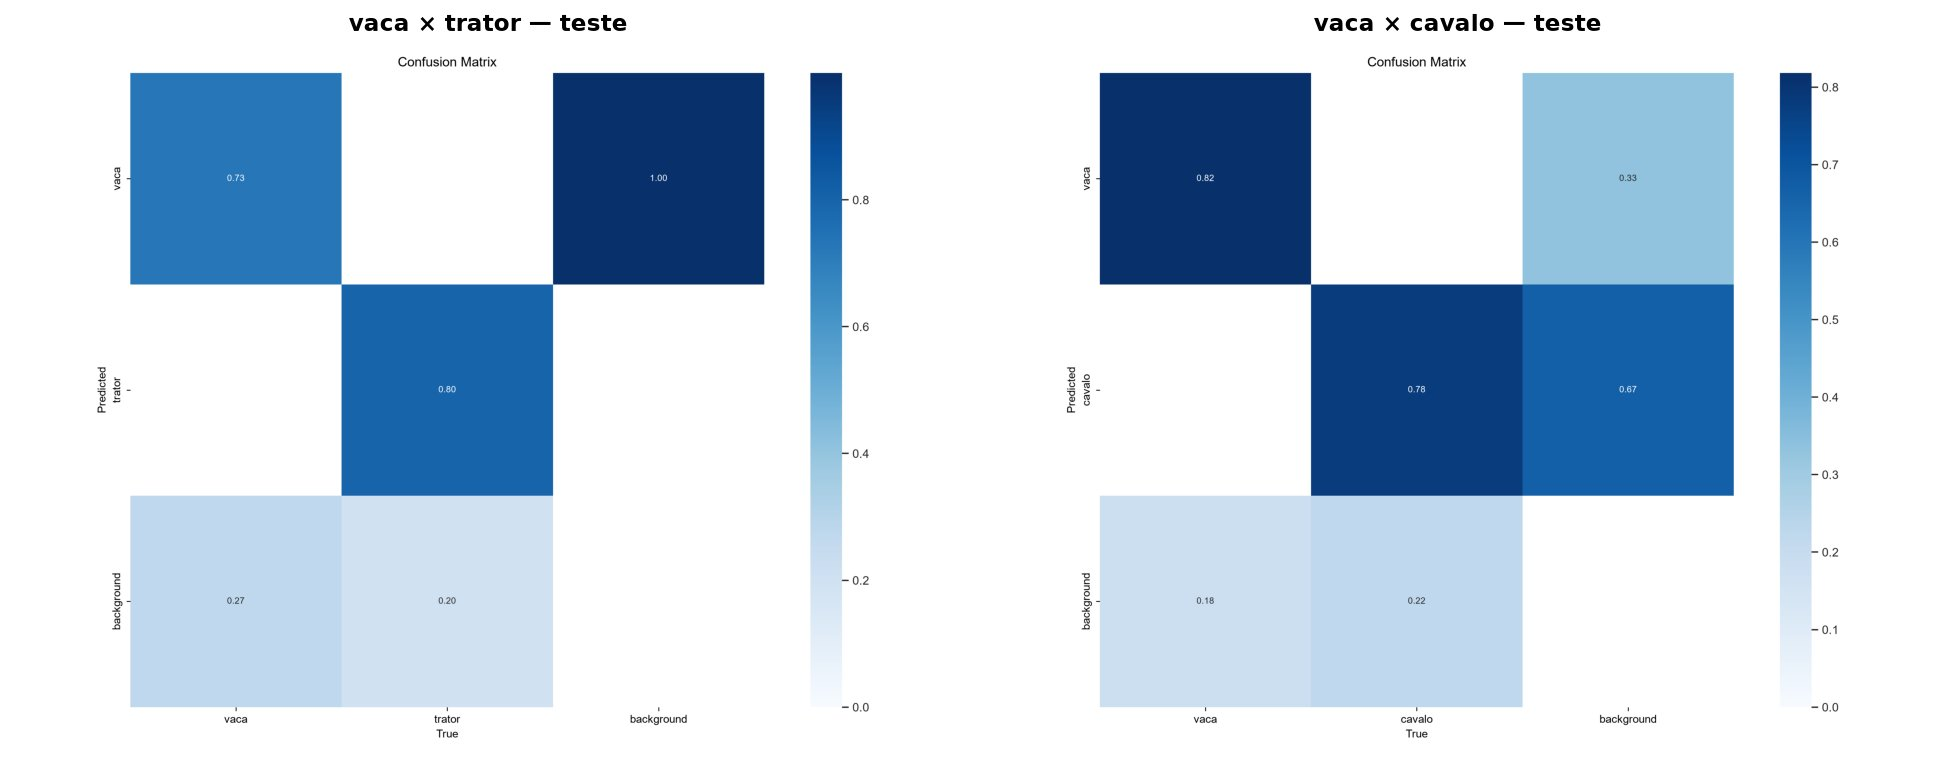

In [9]:
CONFUSION_DPI = 140


def plot_yolo_confusions(name: str) -> None:
    fig, axes = plt.subplots(1, len(PAIRS), figsize=(7 * len(PAIRS), 5.4))
    for ax, pair in zip(axes, PAIRS):
        ax.imshow(Image.open(RUNS_DIR / "val" / f"{RUN_NAMES[pair]}_test" / "confusion_matrix.png"))
        ax.set_title(f"{pair} — teste", fontweight="bold")
        ax.axis("off")
    fig.tight_layout()
    save_photo_grid(fig, name, dpi=CONFUSION_DPI)


plot_yolo_confusions("matriz_confusao_yolo.png")

### A.6 Detecções de cada modelo, uma única vez

Para as análises seguintes (casamento objeto a objeto aqui, decisão por imagem na parte B), cada modelo passa **uma vez** por cada imagem de validação e teste, via `torch.hub` a partir do clone local, com limiar baixo (`AP_CONF`); o limiar de uso `CONF_THRES` = 0,25 (o padrão do `detect.py`, o mesmo da Entrega 1) é aplicado depois. A saída bruta fica guardada com as classes do próprio modelo e é traduzida para o vocabulário do par:

* YOLO customizado: identidade;
* YOLO tradicional (COCO), mapeamento **fixado antes de olhar os resultados**: em vaca × cavalo, `cow → vaca` e `horse → cavalo` (as duas classes existem no COCO); em vaca × trator, o mapeamento da Entrega 2 (`cow → vaca`; `truck`, `car`, `bus → trator`). Outras classes COCO são descartadas.

In [10]:
AP_CONF = 0.001
CONF_THRES = 0.25
COCO_WEIGHTS = YOLO_DIR / BASE_WEIGHTS
CUSTOM, COCO = "YOLO customizado (e60)", "YOLO tradicional (COCO)"
YOLO_APPROACHES = (COCO, CUSTOM)
COCO_MAPS = {PAIR_OLD: {"cow": "vaca", "truck": "trator", "car": "trator", "bus": "trator"},
             PAIR_NEW: {"cow": "vaca", "horse": "cavalo"}}


def load_yolo(weights: Path, device: str = TORCH_DEVICE, conf: float = AP_CONF) -> torch.nn.Module:
    with quiet_yolo():
        model = torch.hub.load(str(YOLO_DIR), "custom", path=str(weights), source="local", verbose=False).to(device)
    model.conf = conf
    return model


def free_gpu() -> None:
    if torch.cuda.is_available():
        torch.cuda.empty_cache()


def raw_detections(model: torch.nn.Module, path: Path) -> list[Detection]:
    rows = model(str(path)).xyxy[0].tolist()
    return [(model.names[int(cls)], conf, [x1, y1, x2, y2]) for x1, y1, x2, y2, conf, cls in rows]


def detect_images(weights: Path, paths: list[Path]) -> dict[str, list[Detection]]:
    model = load_yolo(weights)
    detections = {path.name: raw_detections(model, path) for path in paths}
    del model
    free_gpu()
    return detections


def map_detections(raw: list[Detection], class_map: dict[str, str]) -> list[Detection]:
    return [(class_map[label], conf, box) for label, conf, box in raw if label in class_map]


def confident(detections: list[Detection]) -> list[Detection]:
    return [detection for detection in detections if detection[1] >= CONF_THRES]


RAW = {(pair, CUSTOM): detect_images(CUSTOM_WEIGHTS[pair], EVAL_PATHS[pair][VAL_TEST_SET]) for pair in PAIRS}
RAW.update({(pair, COCO): detect_images(COCO_WEIGHTS, EVAL_PATHS[pair][VAL_TEST_SET]) for pair in PAIRS})
CLASS_MAPS = {(pair, CUSTOM): {name: name for name in classes_of(pair)} for pair in PAIRS}
CLASS_MAPS.update({(pair, COCO): COCO_MAPS[pair] for pair in PAIRS})
DETECTIONS = {key: {name: map_detections(raw, CLASS_MAPS[key]) for name, raw in images.items()} for key, images in RAW.items()}
print(f"Detecções calculadas para {len(DETECTIONS)} combinações par × modelo")

Detecções calculadas para 4 combinações par × modelo


### A.7 Análise objeto a objeto: quem foi encontrado, perdido ou **trocado**

O mesmo casamento da seção 6.4 da Entrega 1: as previsões de cada imagem (confiança ≥ `CONF_THRES`) são percorridas da mais para a menos confiante, e cada uma é casada com a caixa real ainda livre de maior IoU, **sem olhar a classe**. Com IoU ≥ 0,5, o par é um acerto (**VP**) se as classes coincidem ou uma **troca** se não; previsão sem par é **alarme falso (FP)**; caixa real sem par é **objeto perdido (FN)**. Uma troca conta como erro na precisão e na revocação.

Reportamos o teste (como na Entrega 1) e val+teste (o dobro de objetos, com a ressalva de que a validação escolheu o `best.pt` do modelo customizado), para os dois modelos YOLO e os dois pares. O YOLO do COCO também pode trocar `cow` por `horse`: é a referência do quanto a troca vem da semelhança entre as classes e não do nosso treino.

In [11]:
MATCH_IOU = 0.5
BACKGROUND = "fundo"
TP, FN, FP, SWAP = "VP", "FN", "FP", "troca"
OUTCOMES = (TP, FN, FP, SWAP)


def box_area(box: list[float]) -> float:
    return max(0.0, box[2] - box[0]) * max(0.0, box[3] - box[1])


def iou(first: list[float], second: list[float]) -> float:
    inter = box_area([max(first[0], second[0]), max(first[1], second[1]), min(first[2], second[2]), min(first[3], second[3])])
    return inter / (box_area(first) + box_area(second) - inter + 1e-9)


def match_record(truth: Truth | None, prediction: Detection | None, overlap: float) -> dict[str, Any]:
    real = truth[0] if truth else BACKGROUND
    predicted = prediction[0] if prediction else BACKGROUND
    outcome = FN if prediction is None else FP if truth is None else TP if real == predicted else SWAP
    return {"classe real": real, "classe prevista": predicted, "resultado": outcome, "IoU": overlap,
            "confiança": prediction[1] if prediction else np.nan,
            "caixa real": truth[1] if truth else None, "caixa prevista": prediction[2] if prediction else None}


def match_image(truths: list[Truth], predictions: list[Detection]) -> list[dict[str, Any]]:
    free, records = set(range(len(truths))), []
    for prediction in sorted(predictions, key=lambda detection: -detection[1]):
        overlaps = {index: iou(truths[index][1], prediction[2]) for index in free}
        index = max(overlaps, key=overlaps.get, default=None)
        if index is not None and overlaps[index] >= MATCH_IOU:
            free.discard(index)
            records.append(match_record(truths[index], prediction, overlaps[index]))
        else:
            records.append(match_record(None, prediction, 0.0))
    return records + [match_record(truths[index], None, 0.0) for index in sorted(free)]


def match_set(pair: str, approach: str, set_name: str) -> pd.DataFrame:
    rows = [{"imagem": path.name, "classe da foto": class_from_name(path), **record}
            for path in EVAL_PATHS[pair][set_name]
            for record in match_image(TRUTHS[pair][path.name], confident(DETECTIONS[(pair, approach)][path.name]))]
    return pd.DataFrame(rows)


def object_summary(matches: pd.DataFrame) -> dict[str, Any]:
    counts = matches["resultado"].value_counts().reindex(list(OUTCOMES), fill_value=0).astype(int)
    real = counts[TP] + counts[FN] + counts[SWAP]
    predicted = counts[TP] + counts[FP] + counts[SWAP]
    return {"objetos reais": real, **counts.to_dict(), "precisão": counts[TP] / predicted if predicted else 0.0,
            "revocação": counts[TP] / real if real else 0.0, "F1": 2 * counts[TP] / (real + predicted) if real + predicted else 0.0}


MATCHES = {(pair, approach, set_name): match_set(pair, approach, set_name)
           for pair in PAIRS for approach in YOLO_APPROACHES for set_name in (TEST_SET, VAL_TEST_SET)}
OBJECT_TABLE = pd.DataFrame([{"par": pair, "modelo": approach, "conjunto": set_name, **object_summary(matches)}
                             for (pair, approach, set_name), matches in MATCHES.items()]).set_index(["par", "modelo", "conjunto"])
OBJECT_TABLE.to_csv(FIGURES_DIR / "deteccao_objeto_a_objeto.csv")
OBJECT_TABLE.style.format(precision=3, decimal=",", subset=["precisão", "revocação", "F1"])

Matriz de confusão em **contagens** do YOLO customizado vaca × cavalo em val+teste (linhas: classe real; colunas: classe prevista; `fundo` = nenhum objeto). Com tão poucos objetos, contagens absolutas são mais fáceis de ler do que a matriz normalizada do YOLOv5.

In [12]:
def confusion_counts(matches: pd.DataFrame, pair: str) -> pd.DataFrame:
    labels = [*classes_of(pair), BACKGROUND]
    table = pd.crosstab(matches["classe real"], matches["classe prevista"])
    return table.reindex(index=labels, columns=labels, fill_value=0).rename_axis(index="real ↓ / prevista →", columns=None)


confusion_counts(MATCHES[(PAIR_NEW, CUSTOM, VAL_TEST_SET)], PAIR_NEW)

,vaca,cavalo,fundo
real ↓ / prevista →,,,
vaca,16,0,11
cavalo,0,12,3
fundo,8,1,0


### A.8 Detecções nas imagens de teste

As 8 imagens de teste de vaca × cavalo com as caixas do YOLO customizado desenhadas sobre a foto original: azul = acerto (VP), vermelho = alarme falso, magenta = **troca de classe**, verde pontilhado = caixa real encontrada, laranja tracejado = caixa real perdida.

Figura salva em extra/figuras/deteccoes_teste.png (243 KB)


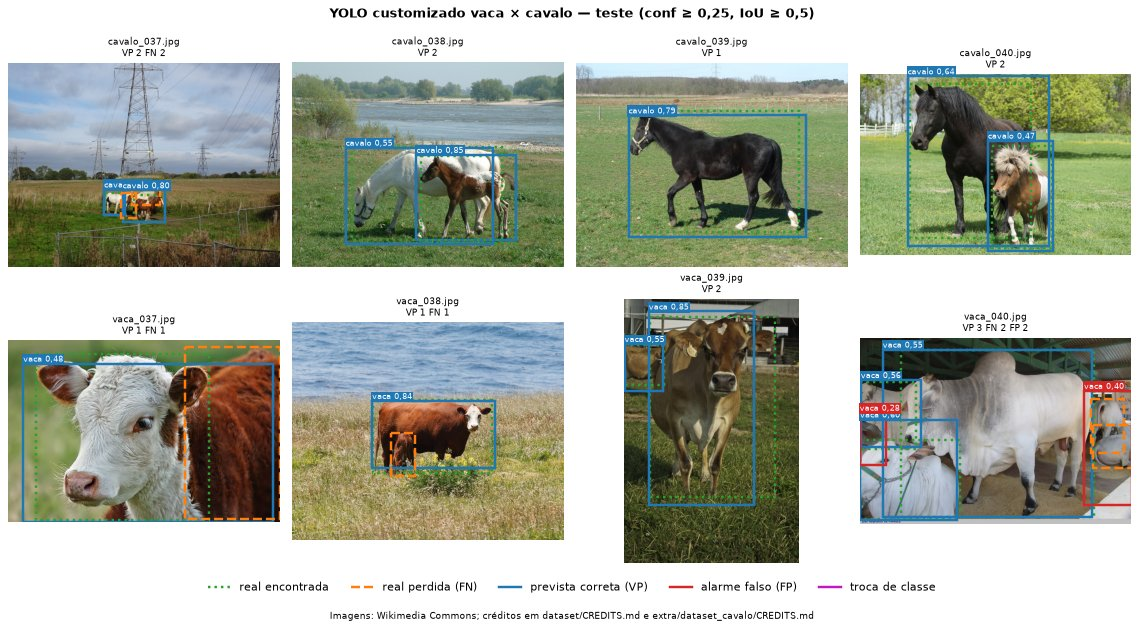

In [13]:
BOX_STYLES = {"found": ("#2ca02c", ":"), "missed": ("#ff7f0e", "--"), TP: ("#1f77b4", "-"), FP: ("#d62728", "-"),
              SWAP: ("#c218c2", "-")}
BOX_LEGEND = {"found": "real encontrada", "missed": "real perdida (FN)", TP: "prevista correta (VP)",
              FP: "alarme falso (FP)", SWAP: "troca de classe"}
DETECTION_CELL = 3.6


def draw_box(ax: plt.Axes, box: list[float], style: str, label: str = "") -> None:
    color, line = BOX_STYLES[style]
    ax.add_patch(Rectangle((box[0], box[1]), box[2] - box[0], box[3] - box[1], fill=False, edgecolor=color,
                           linestyle=line, linewidth=2.2))
    if label:
        ax.text(box[0], box[1], label, color="white", fontsize=7.5, va="bottom",
                bbox={"facecolor": color, "edgecolor": "none", "pad": 1})


def draw_record(ax: plt.Axes, record: dict[str, Any]) -> None:
    if record["caixa real"] is not None:
        draw_box(ax, record["caixa real"], "missed" if record["resultado"] == FN else "found")
    if record["caixa prevista"] is not None:
        draw_box(ax, record["caixa prevista"], record["resultado"], f"{record['classe prevista']} {fmt_num(record['confiança'], 2)}")


def image_title(image: str, matches: pd.DataFrame) -> str:
    counts = matches["resultado"].value_counts()
    return f"{image}\n" + " ".join(f"{key} {counts[key]}" for key in OUTCOMES if counts.get(key, 0))


def plot_detections(pair: str, matches: pd.DataFrame, images: list[str], title: str, name: str, columns: int = 4) -> None:
    rows = -(-len(images) // columns)
    fig, axes = plt.subplots(rows, columns, figsize=(DETECTION_CELL * columns, DETECTION_CELL * rows + 0.6), squeeze=False)
    for ax in axes.flat:
        ax.axis("off")
    for ax, image in zip(axes.flat, images):
        subset = matches[matches["imagem"] == image]
        ax.imshow(Image.open(PATH_INDEX[pair][image]))
        for record in subset.to_dict("records"):
            draw_record(ax, record)
        ax.set_title(image_title(image, subset), fontsize=8.5)
    handles = [Line2D([], [], color=color, linestyle=line, linewidth=2.2) for color, line in BOX_STYLES.values()]
    fig.legend(handles, BOX_LEGEND.values(), loc="lower center", ncol=len(handles), frameon=False, bbox_to_anchor=(0.5, 0.025))
    fig.suptitle(title, fontweight="bold")
    fig.text(0.5, 0, CREDITS_CAPTION, ha="center", fontsize=8)
    fig.tight_layout(rect=(0, 0.07, 1, 1))
    save_photo_grid(fig, name)


test_matches = MATCHES[(PAIR_NEW, CUSTOM, TEST_SET)]
plot_detections(PAIR_NEW, test_matches, [path.name for path in EVAL_PATHS[PAIR_NEW][TEST_SET]],
                f"YOLO customizado vaca × cavalo — teste (conf ≥ {fmt_num(CONF_THRES, 2)}, IoU ≥ {fmt_num(MATCH_IOU, 1)})",
                "deteccoes_teste.png")

### A.9 Piores erros e leitura gerada

As imagens de val+teste com mais erros (FN + FP + trocas) do YOLO customizado vaca × cavalo, da pior para a melhor (até 4), e a leitura gerada a partir das tabelas: objetos encontrados por classe e trocas de classe nos dois pares, para os dois modelos YOLO.

Figura salva em extra/figuras/erros_deteccao.png (381 KB)


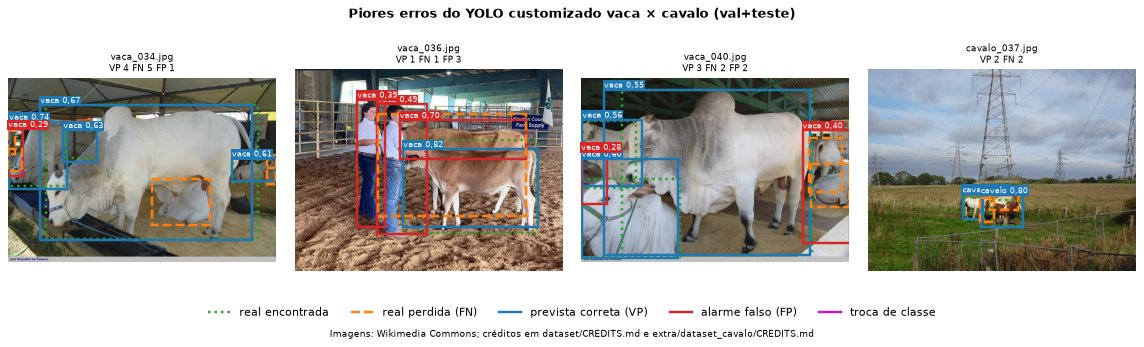

#### Leitura objeto a objeto
- **YOLO customizado (e60) · vaca × trator** (val+teste): objetos encontrados `vaca` 16 de 27, `trator` 8 de 9; nenhuma troca de classe
- **YOLO customizado (e60) · vaca × cavalo** (val+teste): objetos encontrados `vaca` 16 de 27, `cavalo` 12 de 15; nenhuma troca de classe
- **YOLO tradicional (COCO) · vaca × trator** (val+teste): objetos encontrados `vaca` 17 de 27, `trator` 7 de 9; nenhuma troca de classe
- **YOLO tradicional (COCO) · vaca × cavalo** (val+teste): objetos encontrados `vaca` 17 de 27, `cavalo` 13 de 15; nenhuma troca de classe

In [14]:
MAX_ERROR_IMAGES = 4


def errors_per_image(matches: pd.DataFrame) -> pd.Series:
    errors = matches[matches["resultado"] != TP]
    return errors.groupby("imagem").size().sort_values(ascending=False, kind="stable")


def class_recall_text(matches: pd.DataFrame, pair: str) -> str:
    real = matches[matches["classe real"] != BACKGROUND]
    found = real.assign(acerto=real["resultado"] == TP).groupby("classe real")["acerto"].agg(["sum", "size"])
    return ", ".join(f"`{name}` {int(found.loc[name, 'sum'])} de {int(found.loc[name, 'size'])}"
                     for name in classes_of(pair) if name in found.index)


def swap_text(matches: pd.DataFrame) -> str:
    swaps = matches[matches["resultado"] == SWAP]
    if swaps.empty:
        return "nenhuma troca de classe"
    kinds = (swaps["classe real"] + " → " + swaps["classe prevista"]).value_counts()
    return plural(len(swaps), "troca", "trocas") + " (" + ", ".join(f"{kind} ×{count}" for kind, count in kinds.items()) + ")"


def detection_lines() -> list[str]:
    return [f"**{approach} · {pair}** (val+teste): objetos encontrados {class_recall_text(MATCHES[(pair, approach, VAL_TEST_SET)], pair)}; "
            f"{swap_text(MATCHES[(pair, approach, VAL_TEST_SET)])}"
            for approach in (CUSTOM, COCO) for pair in PAIRS]


worst = errors_per_image(MATCHES[(PAIR_NEW, CUSTOM, VAL_TEST_SET)]).index[:MAX_ERROR_IMAGES].tolist()
if worst:
    plot_detections(PAIR_NEW, MATCHES[(PAIR_NEW, CUSTOM, VAL_TEST_SET)], worst,
                    "Piores erros do YOLO customizado vaca × cavalo (val+teste)", "erros_deteccao.png")
else:
    print("Nenhum erro de detecção em val+teste.")
show_markdown(detection_lines(), "Leitura objeto a objeto")

---
## B. Espelho da Entrega 2 — YOLO tradicional × YOLO customizado × CNN do zero

Mesmo protocolo de comparação justa da Entrega 2, agora nos dois pares:

* as três abordagens são avaliadas **nas mesmas imagens** (teste, e val+teste com o viés de seleção já discutido na Entrega 2) e com as mesmas funções;
* decisão por imagem: nos YOLO, a classe da detecção mais confiante com confiança ≥ `CONF_THRES` (sem detecção, a imagem recebe `nenhum` e conta como erro); na CNN, a probabilidade contra 0,5;
* toda acurácia vem com **intervalo de Wilson** a 95%, e as comparações pareadas usam o **teste exato de McNemar**;
* a CNN é a da Entrega 2 (mesma arquitetura, *augmentation*, *early stopping* e as mesmas 5 sementes), treinada nos dois pares com o mesmo código.

### B.1 Métricas por imagem

In [15]:
NO_DETECTION = "nenhum"
CI_COLUMN = f"IC{CONFIDENCE_LEVEL:.0%} Wilson"


def proportion_interval(hits: int, total: int, method: str = "wilson") -> tuple[float, float]:
    interval = binomtest(hits, total).proportion_ci(CONFIDENCE_LEVEL, method=method)
    return float(interval.low), float(interval.high)


def image_metrics(y_true: list[str], y_pred: list[str]) -> dict[str, Any]:
    hits = sum(truth == prediction for truth, prediction in zip(y_true, y_pred))
    cow = [truth == prediction for truth, prediction in zip(y_true, y_pred) if truth == "vaca"]
    other = [truth == prediction for truth, prediction in zip(y_true, y_pred) if truth != "vaca"]
    return {"acertos": hits, "n": len(y_true), "acurácia": hits / len(y_true),
            CI_COLUMN: fmt_interval(*proportion_interval(hits, len(y_true))),
            "acerto vaca": float(np.mean(cow)), "acerto 2ª classe": float(np.mean(other))}


def mcnemar_exact(y_true: list[str], first: list[str], second: list[str]) -> tuple[int, int, float]:
    only_first = sum(a == truth != b for truth, a, b in zip(y_true, first, second))
    only_second = sum(b == truth != a for truth, a, b in zip(y_true, first, second))
    discordant = only_first + only_second
    return only_first, only_second, float(binomtest(only_first, discordant).pvalue) if discordant else 1.0


def top_detection(detections: list[Detection]) -> tuple[str, float]:
    best = max(confident(detections), key=lambda detection: detection[1], default=None)
    return (best[0], best[1]) if best else (NO_DETECTION, 0.0)

### B.2 Decisões dos dois YOLO

Para cada par e modelo, a decisão por imagem a partir das detecções já calculadas na seção A.6. A linha gerada mostra, para o YOLO do COCO, as classes **fora do vocabulário do par** que ele detectou nas imagens de val+teste e que o mapeamento descartou (por exemplo, `sheep` ou `dog` numa foto de vaca ou cavalo).

In [16]:
def yolo_decisions(pair: str, approach: str) -> dict[str, tuple[str, float]]:
    return {name: top_detection(detections) for name, detections in DETECTIONS[(pair, approach)].items()}


def set_predictions(pair: str, decisions: dict[str, tuple[str, float]]) -> dict[str, list[str]]:
    return {set_name: [decisions[path.name][0] for path in paths] for set_name, paths in EVAL_PATHS[pair].items()}


def unmapped_line(pair: str) -> str:
    labels = pd.Series([label for detections in RAW[(pair, COCO)].values() for label, _, _ in confident(detections)
                        if label not in COCO_MAPS[pair]], dtype=object).value_counts()
    listing = ", ".join(f"`{label}` ×{count}" for label, count in labels.items()) or "nenhuma"
    return f"YOLO tradicional · {pair}: classes COCO descartadas pelo mapeamento (conf ≥ {fmt_num(CONF_THRES, 2)}): {listing}"


DECISIONS = {(pair, approach): yolo_decisions(pair, approach) for pair in PAIRS for approach in YOLO_APPROACHES}
PREDICTIONS = {key: set_predictions(key[0], decisions) for key, decisions in DECISIONS.items()}
show_markdown([unmapped_line(pair) for pair in PAIRS], "Detecções COCO fora do par")

#### Detecções COCO fora do par
- YOLO tradicional · vaca × trator: classes COCO descartadas pelo mapeamento (conf ≥ 0,25): `person` ×14, `bird` ×1
- YOLO tradicional · vaca × cavalo: classes COCO descartadas pelo mapeamento (conf ≥ 0,25): `person` ×3, `clock` ×1, `bird` ×1

### B.3 CNN do zero da Entrega 2

A mesma rede da seção 11 da Entrega 2: imagens 128×128, *augmentation* (flip, rotação, zoom, contraste), três blocos `Conv2D + MaxPooling` (32→128 filtros), `GlobalAveragePooling`, *dropout* 0,3 e saída sigmoide; Adam 1e-3, até 150 épocas com *early stopping* na perda de validação (paciência 20 a partir da época 30, restaurando os melhores pesos). O rótulo 1 é a segunda classe do par (`trator` ou `cavalo`).

In [17]:
CNN_IMG_SIZE = 128
CNN_BATCH_SIZE = 16
CNN_MAX_EPOCHS = 150
CNN_PATIENCE = 20
CNN_MIN_EPOCHS = 30
CNN_FILTERS = (32, 64, 128)
CNN_KERNEL = 3
CNN_DROPOUT = 0.3
CNN_LEARNING_RATE = 1e-3
CNN_AUG_ROTATION = 0.1
CNN_AUG_ZOOM = 0.15
CNN_AUG_CONTRAST = 0.2
CNN_SEEDS = (SEED, 7, 123, 2024, 31337)


def load_cnn_array(path: Path) -> np.ndarray:
    return np.asarray(Image.open(path).convert("RGB").resize((CNN_IMG_SIZE, CNN_IMG_SIZE)), dtype=np.float32)


def label_index(pair: str, path: Path) -> int:
    return classes_of(pair).index(class_from_name(path))


def cnn_arrays(pair: str) -> dict[str, tuple[np.ndarray, np.ndarray]]:
    sets = {"train": PATHS[pair]["train"], "val": PATHS[pair]["val"], **EVAL_PATHS[pair]}
    return {name: (np.stack([load_cnn_array(path) for path in paths]),
                   np.array([label_index(pair, path) for path in paths])) for name, paths in sets.items()}


def build_cnn() -> keras.Model:
    augmentation = keras.Sequential([layers.RandomFlip("horizontal"), layers.RandomRotation(CNN_AUG_ROTATION),
                                     layers.RandomZoom(CNN_AUG_ZOOM), layers.RandomContrast(CNN_AUG_CONTRAST)], name="augmentation")
    conv_blocks = [layer for filters in CNN_FILTERS
                   for layer in (layers.Conv2D(filters, CNN_KERNEL, padding="same", activation="relu"), layers.MaxPooling2D())]
    model = keras.Sequential([keras.Input((CNN_IMG_SIZE, CNN_IMG_SIZE, 3)), augmentation, layers.Rescaling(1.0 / 255),
                              *conv_blocks, layers.GlobalAveragePooling2D(), layers.Dropout(CNN_DROPOUT),
                              layers.Dense(1, activation="sigmoid")])
    model.compile(optimizer=keras.optimizers.Adam(CNN_LEARNING_RATE), loss="binary_crossentropy", metrics=["accuracy"])
    return model


def cnn_probabilities(model: keras.Model, x: np.ndarray) -> np.ndarray:
    return model(x, training=False).numpy()[:, 0]


def to_labels(pair: str, probabilities: np.ndarray) -> list[str]:
    return [classes_of(pair)[int(probability >= DECISION_THRESHOLD)] for probability in probabilities]


CNN_DATA = {pair: cnn_arrays(pair) for pair in PAIRS}
print({pair: {name: x.shape for name, (x, _) in sets.items()} for pair, sets in CNN_DATA.items()})

{'vaca × trator': {'train': (64, 128, 128, 3), 'val': (8, 128, 128, 3), 'teste': (8, 128, 128, 3), 'val+teste': (16, 128, 128, 3)}, 'vaca × cavalo': {'train': (64, 128, 128, 3), 'val': (8, 128, 128, 3), 'teste': (8, 128, 128, 3), 'val+teste': (16, 128, 128, 3)}}


### B.4 Treino das 5 sementes nos dois pares

Cada semente treina a mesma receita do zero, com os mesmos splits; o tempo é cronometrado. A semente principal (42) é o modelo "entregue" da CNN, usado nas matrizes de confusão, no Grad-CAM e no benchmark de tempo, como na Entrega 2 (não escolhemos a melhor semente, o que seria selecionar pelo resultado). A tabela resume a acurácia de cada par por semente.

In [18]:
def train_cnn(pair: str, seed: int) -> dict[str, Any]:
    keras.backend.clear_session()
    set_seeds(seed)
    data = CNN_DATA[pair]
    model = build_cnn()
    stopper = keras.callbacks.EarlyStopping(monitor="val_loss", patience=CNN_PATIENCE, restore_best_weights=True,
                                            start_from_epoch=CNN_MIN_EPOCHS)
    start = time.perf_counter()
    history = model.fit(*data["train"], validation_data=data["val"], epochs=CNN_MAX_EPOCHS, batch_size=CNN_BATCH_SIZE,
                        callbacks=[stopper], verbose=0)
    probabilities = {set_name: cnn_probabilities(model, data[set_name][0]) for set_name in EVAL_PATHS[pair]}
    return {"model": model if seed == SEED else None, "seconds": time.perf_counter() - start,
            "epochs": len(history.history["loss"]), "probabilities": probabilities,
            "predictions": {set_name: to_labels(pair, values) for set_name, values in probabilities.items()}}


def seed_row(pair: str, seed: int, run: dict[str, Any]) -> dict[str, Any]:
    return {"par": pair, "semente": seed, "épocas": run["epochs"], "treino (s)": run["seconds"],
            **{f"acurácia {set_name}": image_metrics(Y_TRUE[pair][set_name], run["predictions"][set_name])["acurácia"]
               for set_name in EVAL_PATHS[pair]}}


CNN_RUNS = {pair: {seed: train_cnn(pair, seed) for seed in CNN_SEEDS} for pair in PAIRS}
CNN_SEED_TABLE = pd.DataFrame([seed_row(pair, seed, run) for pair, runs in CNN_RUNS.items() for seed, run in runs.items()])
CNN_SEED_TABLE.to_csv(FIGURES_DIR / "cnn_sementes.csv", index=False)
CNN_MODEL_FILE = RUNS_DIR / f"cnn_vaca_cavalo_seed{SEED}.keras"
CNN_RUNS[PAIR_NEW][SEED]["model"].save(CNN_MODEL_FILE)
CNN_SEED_TABLE.groupby("par").agg(["mean", "std", "min", "max"]).drop(columns="semente").style.format(precision=3, decimal=",")

### B.5 Tabela unificada de classificação por imagem

As mesmas imagens e métricas para todas as abordagens, nos dois pares e nos dois conjuntos. Linhas de referência: a **CNN, média das 5 sementes** (o intervalo é a faixa mín–máx entre sementes, não Wilson) e uma **referência constante** que sempre responde `vaca`, o piso do problema. `acerto vaca` e `acerto 2ª classe` são as acurácias dentro de cada classe: como as vacas são as mesmas nos dois pares, uma queda em `acerto vaca` mostra vacas sendo chamadas de cavalo. A tabela vai para `extra/figuras/classificacao_por_imagem.csv`.

In [19]:
CNN_MAIN = f"CNN do zero (semente {SEED})"
CNN_MEAN = f"CNN do zero (média de {len(CNN_SEEDS)} sementes)"
BASELINE = "referência: sempre vaca"
CLASSIFIERS = (COCO, CUSTOM, CNN_MAIN)

for pair in PAIRS:
    PREDICTIONS[(pair, CNN_MAIN)] = CNN_RUNS[pair][SEED]["predictions"]
    PREDICTIONS[(pair, BASELINE)] = {set_name: ["vaca"] * len(paths) for set_name, paths in EVAL_PATHS[pair].items()}


def seed_mean_row(pair: str, set_name: str) -> dict[str, Any]:
    per_seed = pd.DataFrame([image_metrics(Y_TRUE[pair][set_name], run["predictions"][set_name]) for run in CNN_RUNS[pair].values()])
    return {"par": pair, "conjunto": set_name, "abordagem": CNN_MEAN, **per_seed.mean(numeric_only=True).to_dict(),
            CI_COLUMN: f"faixa {fmt_num(per_seed['acurácia'].min(), 2)}–{fmt_num(per_seed['acurácia'].max(), 2)}"}


IMAGE_ROWS = [{"par": pair, "conjunto": set_name, "abordagem": approach, **image_metrics(Y_TRUE[pair][set_name], predictions[set_name])}
              for (pair, approach), predictions in PREDICTIONS.items() for set_name in EVAL_PATHS[pair]]
IMAGE_ROWS += [seed_mean_row(pair, set_name) for pair in PAIRS for set_name in EVAL_PATHS[pair]]
APPROACH_ORDER = [COCO, CUSTOM, CNN_MAIN, CNN_MEAN, BASELINE]
IMAGE_TABLE = (pd.DataFrame(IMAGE_ROWS).assign(ordem=lambda frame: frame["abordagem"].map(APPROACH_ORDER.index))
               .sort_values(["conjunto", "par", "ordem"], ascending=[False, True, True]).drop(columns="ordem")
               .set_index(["conjunto", "par", "abordagem"]))
IMAGE_TABLE.to_csv(FIGURES_DIR / "classificacao_por_imagem.csv")
IMAGE_TABLE.style.format(precision=3, decimal=",", subset=["acurácia", "acerto vaca", "acerto 2ª classe"]).format(
    precision=1, decimal=",", subset=["acertos"])

### B.6 As diferenças entre abordagens são significativas?

Teste exato de McNemar para cada par de abordagens, nas mesmas 16 imagens de val+teste de cada par. `só A acerta` e `só B acerta` são as imagens discordantes, as únicas que informam qual é melhor. Com 16 imagens, uma abordagem só é declarada melhor (p < 0,05) se acertar pelo menos 6 imagens que a outra erra sem errar nenhuma que ela acerta; por isso "não significativo" aqui significa amostra insuficiente, não modelos iguais.

In [20]:
def mcnemar_rows(pair: str, set_name: str = VAL_TEST_SET) -> list[dict[str, Any]]:
    rows = []
    for first, second in combinations(CLASSIFIERS, 2):
        only_first, only_second, p = mcnemar_exact(Y_TRUE[pair][set_name], PREDICTIONS[(pair, first)][set_name],
                                                   PREDICTIONS[(pair, second)][set_name])
        rows.append({"par": pair, "A": first, "B": second, "só A acerta": only_first, "só B acerta": only_second,
                     "p (McNemar exato)": p, "significativo": p < SIGNIFICANCE})
    return rows


MCNEMAR_E2 = pd.DataFrame([row for pair in PAIRS for row in mcnemar_rows(pair)]).set_index(["par", "A", "B"])
MCNEMAR_E2.style.format({"p (McNemar exato)": lambda value: fmt_num(value, 3)})

### B.7 Matrizes de confusão por imagem (vaca × cavalo, val+teste)

Uma matriz por abordagem; a coluna `nenhum` aparece quando um YOLO não tem detecção confiante numa imagem. Fora da diagonal, a troca vaca ↔ cavalo no nível da foto.

Figura salva em extra/figuras/confusao_classificacao.png (28 KB)


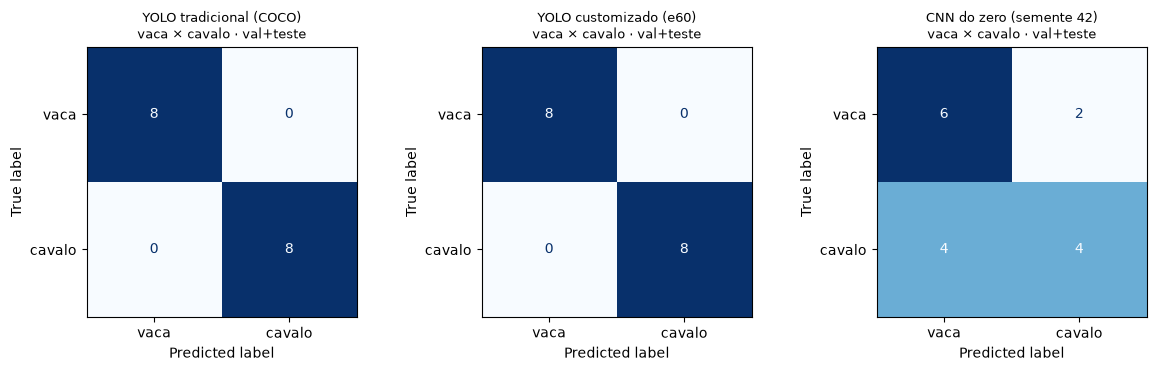

In [21]:
CONFUSION_PANEL = (4.0, 3.7)


def plot_image_confusions(pair: str, set_name: str, name: str) -> None:
    fig, axes = plt.subplots(1, len(CLASSIFIERS), figsize=(CONFUSION_PANEL[0] * len(CLASSIFIERS), CONFUSION_PANEL[1]))
    for ax, approach in zip(axes, CLASSIFIERS):
        predictions = PREDICTIONS[(pair, approach)][set_name]
        labels = [*classes_of(pair), *([NO_DETECTION] if NO_DETECTION in predictions else [])]
        matrix = confusion_matrix(Y_TRUE[pair][set_name], predictions, labels=labels)
        ConfusionMatrixDisplay(matrix, display_labels=labels).plot(ax=ax, colorbar=False, cmap="Blues")
        ax.set_title(f"{approach}\n{pair} · {set_name}", fontsize=9)
    fig.tight_layout()
    save_chart(fig, name)


plot_image_confusions(PAIR_NEW, VAL_TEST_SET, "confusao_classificacao.png")

### B.8 Onde a CNN olha: Grad-CAM nas imagens de teste

O Grad-CAM pondera os mapas de ativação da última convolução pelo gradiente da classe prevista e mostra as regiões que mais pesaram na decisão da CNN (semente 42). Em vaca × trator, a Entrega 2 já mostrava mapas ora no objeto, ora no fundo. Em vaca × cavalo, o fundo é parecido nas duas classes; se a rede ainda acerta, o mapa deveria cair **no animal** (cabeça, pernas, silhueta). Título vermelho com `ERRO` = predição errada.

Figura salva em extra/figuras/gradcam.png (634 KB)


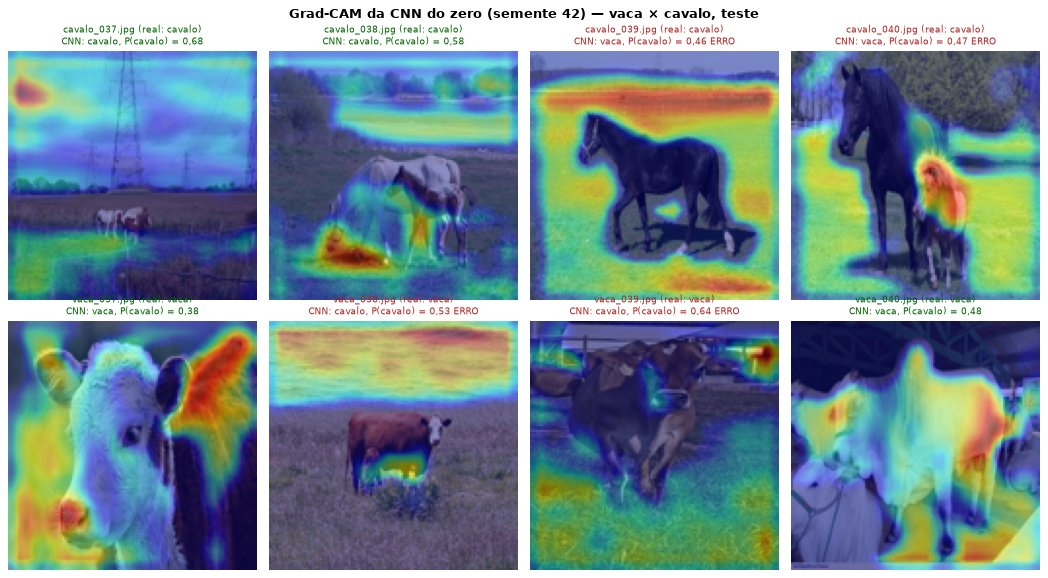

In [22]:
GRADCAM_ALPHA = 0.45
GALLERY_COLUMNS = 4
GALLERY_CELL = (3.3, 3.7)
OK_COLOR, ERROR_COLOR = "darkgreen", "firebrick"


def last_conv_name(model: keras.Model) -> str:
    return [layer.name for layer in model.layers if isinstance(layer, layers.Conv2D)][-1]


def grad_cam(model: keras.Model, image: np.ndarray) -> tuple[np.ndarray, float]:
    target = last_conv_name(model)
    with tf.GradientTape() as tape:
        x = tf.convert_to_tensor(image[None])
        for layer in model.layers:
            x = layer(x, training=False)
            if layer.name == target:
                features = x
                tape.watch(features)
        probability = x[0, 0]
        score = probability if float(probability) >= DECISION_THRESHOLD else 1 - probability
    weights = tf.reduce_mean(tape.gradient(score, features), axis=(1, 2))
    cam = tf.nn.relu(tf.reduce_sum(features * weights[:, None, None, :], axis=-1))[0]
    cam = cam / (tf.reduce_max(cam) + 1e-9)
    return tf.image.resize(cam[..., None], image.shape[:2]).numpy()[..., 0], float(probability)


def gallery_axes(count: int) -> tuple[plt.Figure, np.ndarray]:
    rows = -(-count // GALLERY_COLUMNS)
    fig, axes = plt.subplots(rows, GALLERY_COLUMNS, figsize=(GALLERY_CELL[0] * GALLERY_COLUMNS, GALLERY_CELL[1] * rows), squeeze=False)
    for ax in axes.flat:
        ax.axis("off")
    return fig, axes.ravel()


def plot_grad_cam(pair: str, name: str) -> None:
    model, (images, _) = CNN_RUNS[pair][SEED]["model"], CNN_DATA[pair][TEST_SET]
    second = classes_of(pair)[1]
    fig, axes = gallery_axes(len(images))
    for ax, path, image in zip(axes, EVAL_PATHS[pair][TEST_SET], images):
        heatmap, probability = grad_cam(model, image)
        predicted, truth = to_labels(pair, [probability])[0], class_from_name(path)
        ax.imshow(image.astype(np.uint8))
        ax.imshow(heatmap, cmap="jet", alpha=GRADCAM_ALPHA)
        ax.set_title(f"{path.name} (real: {truth})\nCNN: {predicted}, P({second}) = {fmt_num(probability, 2)}"
                     + ("" if predicted == truth else " ERRO"), fontsize=8, color=OK_COLOR if predicted == truth else ERROR_COLOR)
    fig.suptitle(f"Grad-CAM da CNN do zero (semente {SEED}) — {pair}, teste", fontweight="bold")
    fig.tight_layout()
    save_photo_grid(fig, name)


plot_grad_cam(PAIR_NEW, "gradcam.png")

### B.9 Galeria de erros por imagem (vaca × cavalo, val+teste)

As imagens em que **pelo menos uma** abordagem erra, com a decisão e a confiança de cada uma (confiança da detecção mais forte nos YOLO; probabilidade da classe escolhida na CNN — as escalas não são calibradas entre si). Olhar as fotos é o que explica o erro: animal pequeno ou parcial, pelagem atípica, pose de costas, vários animais.

Figura salva em extra/figuras/erros_classificacao.png (574 KB)


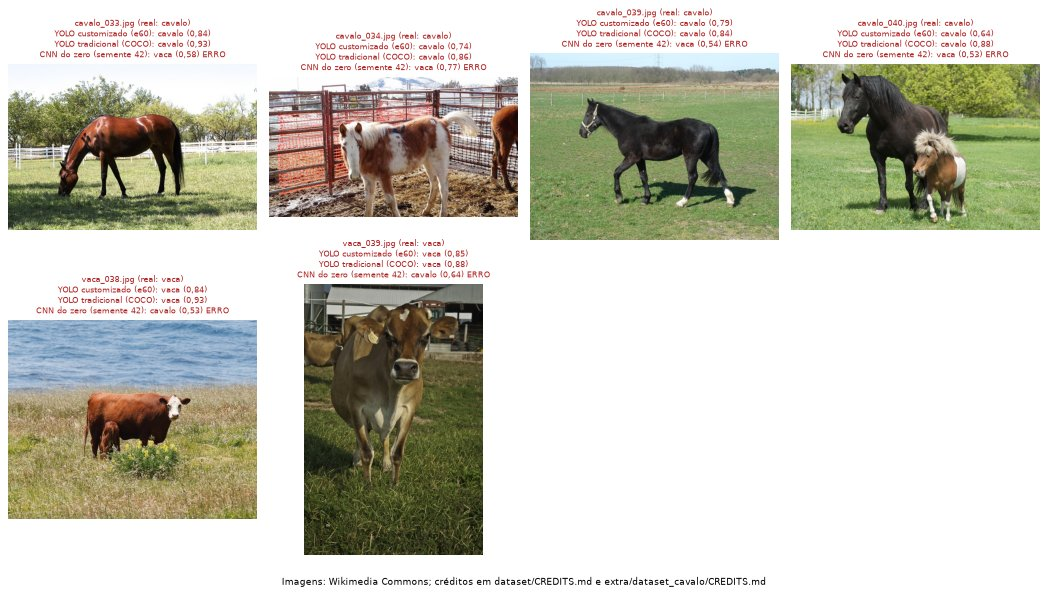

In [23]:
def cnn_decisions(pair: str) -> dict[str, tuple[str, float]]:
    probabilities = CNN_RUNS[pair][SEED]["probabilities"][VAL_TEST_SET]
    labels = to_labels(pair, probabilities)
    return {path.name: (label, float(max(p, 1 - p))) for path, p, label in zip(EVAL_PATHS[pair][VAL_TEST_SET], probabilities, labels)}


def decision_text(decision: tuple[str, float], truth: str) -> str:
    label, confidence = decision
    return f"{label} ({fmt_num(confidence, 2)})" + ("" if label == truth else " ERRO")


def plot_classification_errors(pair: str, name: str) -> list[Path]:
    decisions = {CUSTOM: DECISIONS[(pair, CUSTOM)], COCO: DECISIONS[(pair, COCO)], CNN_MAIN: cnn_decisions(pair)}
    wrong = [path for path in EVAL_PATHS[pair][VAL_TEST_SET]
             if any(found[path.name][0] != class_from_name(path) for found in decisions.values())]
    if not wrong:
        print("Nenhuma abordagem errou alguma imagem de val+teste.")
        return wrong
    fig, axes = gallery_axes(len(wrong))
    for ax, path in zip(axes, wrong):
        truth = class_from_name(path)
        ax.imshow(Image.open(path))
        lines = [f"{approach}: {decision_text(found[path.name], truth)}" for approach, found in decisions.items()]
        ax.set_title("\n".join([f"{path.name} (real: {truth})", *lines]), fontsize=7, color=ERROR_COLOR)
    fig.text(0.5, 0, CREDITS_CAPTION, ha="center", fontsize=8)
    fig.tight_layout(rect=(0, 0.03, 1, 1))
    save_photo_grid(fig, name)
    return wrong


CLASSIFICATION_ERRORS = plot_classification_errors(PAIR_NEW, "erros_classificacao.png")

### B.10 Latência no mesmo hardware

O protocolo da seção 8.5 da Entrega 2: do caminho do arquivo até a predição (leitura, pré-processamento, inferência e NMS nos YOLO), 3 chamadas de aquecimento descartadas, `torch.cuda.synchronize()` antes e depois de cada chamada na GPU, 10 passadas pelas 8 imagens de teste, **mediana** e p90. Os YOLO rodam também na CPU, para comparar no mesmo hardware da CNN quando o TensorFlow não tem GPU (caso do Windows nativo). A CNN é recarregada do arquivo `.keras`, como faria um serviço.

Figura salva em extra/figuras/latencia.png (27 KB)


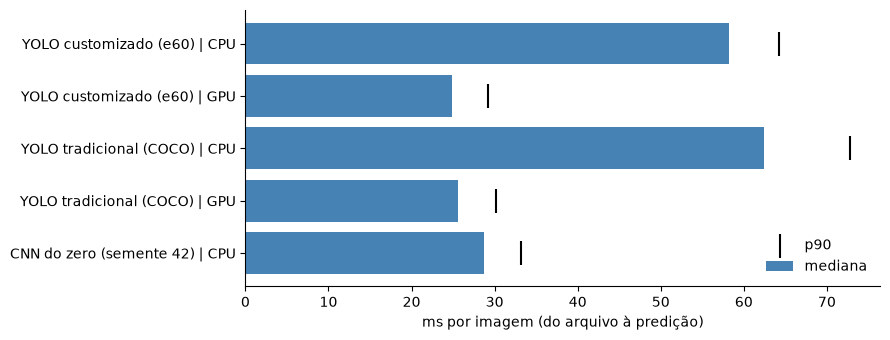

In [24]:
TIMING_WARMUP = 3
TIMING_REPEATS = 10
TIMING_PERCENTILE = 90
MS_IN_SECOND = 1000


def synchronize(device: str) -> None:
    if device == "cuda":
        torch.cuda.synchronize()


def latency_samples(predict: Callable[[Path], object], paths: list[Path], device: str) -> np.ndarray:
    for _ in range(TIMING_WARMUP):
        predict(paths[0])
    samples = []
    for _ in range(TIMING_REPEATS):
        for path in paths:
            synchronize(device)
            start = time.perf_counter()
            predict(path)
            synchronize(device)
            samples.append(MS_IN_SECOND * (time.perf_counter() - start))
    return np.array(samples)


def timing_row(approach: str, device: str, samples: np.ndarray) -> dict[str, Any]:
    median = float(np.median(samples))
    return {"abordagem": approach, "dispositivo": "GPU" if device in ("cuda", "GPU") else "CPU", "mediana (ms/img)": median,
            f"p{TIMING_PERCENTILE} (ms/img)": float(np.percentile(samples, TIMING_PERCENTILE)), "imagens/s": MS_IN_SECOND / median}


def benchmark_yolo(approach: str, weights: Path, device: str) -> dict[str, Any]:
    model = load_yolo(weights, device, CONF_THRES)
    samples = latency_samples(lambda path: raw_detections(model, path), EVAL_PATHS[PAIR_NEW][TEST_SET], device)
    del model
    free_gpu()
    return timing_row(approach, device, samples)


def benchmark_cnn(device: str) -> dict[str, Any]:
    with tf.device(f"/{device}:0"):
        model = keras.models.load_model(CNN_MODEL_FILE)

        def predict(path: Path) -> np.ndarray:
            return cnn_probabilities(model, load_cnn_array(path)[None])

        samples = latency_samples(predict, EVAL_PATHS[PAIR_NEW][TEST_SET], device)
    return timing_row(CNN_MAIN, device, samples)


def plot_latency(table: pd.DataFrame, name: str) -> None:
    labels = [f"{approach} | {device}" for approach, device in table.index]
    fig, ax = plt.subplots(figsize=(9, 0.5 * len(table) + 1))
    positions = np.arange(len(table))
    ax.barh(positions, table["mediana (ms/img)"], color="steelblue", label="mediana")
    ax.scatter(table[f"p{TIMING_PERCENTILE} (ms/img)"], positions, marker="|", s=300, color="black", label=f"p{TIMING_PERCENTILE}")
    ax.set_yticks(positions, labels)
    ax.invert_yaxis()
    ax.set_xlabel("ms por imagem (do arquivo à predição)")
    ax.legend(frameon=False)
    ax.spines[["top", "right"]].set_visible(False)
    fig.tight_layout()
    save_chart(fig, name)


TORCH_DEVICES = ["cpu", *(["cuda"] if torch.cuda.is_available() else [])]
TF_DEVICES = ["CPU", *(["GPU"] if TF_DEVICE == "GPU" else [])]
TIMING_ROWS = [benchmark_yolo(approach, weights, device) for approach, weights in
               ((CUSTOM, CUSTOM_WEIGHTS[PAIR_NEW]), (COCO, COCO_WEIGHTS)) for device in TORCH_DEVICES]
TIMING_ROWS += [benchmark_cnn(device) for device in TF_DEVICES]
TIMING_TABLE = pd.DataFrame(TIMING_ROWS).set_index(["abordagem", "dispositivo"])
TIMING_TABLE.to_csv(FIGURES_DIR / "latencia.csv")
plot_latency(TIMING_TABLE, "latencia.png")
TIMING_TABLE.style.format(precision=1, decimal=",")

---
## C. Espelho do Ir Além — transfer learning × CNN do zero e o atalho do fundo

### C.1 Blocos de construção (idênticos ao Ir Além)

A mesma receita do Ir Além, para que a comparação com os CSVs de vaca × trator seja direta:

* **CNN do zero:** imagens 224×224, *augmentation* (flip, rotação ±8%, zoom ±15%, contraste ±15%), 4 blocos Conv-BN-ReLU-MaxPool com 32→256 filtros (BatchNorm com `momentum=0.9`), GAP, *dropout* 0,4 e saída sigmoide; 40 épocas, Adam 1e-3.
* **MobileNetV2 (ImageNet):** `preprocess_input` dentro do grafo, cabeça GAP → *dropout* 0,3 → sigmoide; estágio 1 com a base congelada (15 épocas, Adam 1e-3) e estágio 2 com *fine tuning* a partir de **`block_15_expand`** (10 épocas, Adam 1e-5), com todos os BatchNorm congelados.

In [25]:
IR_IMG_SIZE = 224
IR_BATCH = 16
AUGMENT_ROTATION = 0.08
AUGMENT_ZOOM = 0.15
AUGMENT_CONTRAST = 0.15
SCRATCH_EPOCHS = 40
SCRATCH_LR = 1e-3
SCRATCH_BN_MOMENTUM = 0.9
SCRATCH_FILTERS = (32, 64, 128, 256)
SCRATCH_DROPOUT = 0.4
TRANSFER_DROPOUT = 0.3
HEAD_EPOCHS = 15
HEAD_LR = 1e-3
FINE_TUNE_EPOCHS = 10
FINE_TUNE_LR = 1e-5
FINE_TUNE_FROM_LAYER = "block_15_expand"
LOG_LOSS_EPSILON = 1e-7
MODEL_SCRATCH = "CNN do zero"
MODEL_TRANSFER = "MobileNetV2 (transfer + fine tuning)"


def build_augmentation() -> keras.Sequential:
    return keras.Sequential([layers.RandomFlip("horizontal"), layers.RandomRotation(AUGMENT_ROTATION),
                             layers.RandomZoom(AUGMENT_ZOOM), layers.RandomContrast(AUGMENT_CONTRAST)], name="aumento_de_dados")


def conv_block(x: keras.KerasTensor, filters: int) -> keras.KerasTensor:
    x = layers.Conv2D(filters, 3, padding="same", use_bias=False)(x)
    x = layers.BatchNormalization(momentum=SCRATCH_BN_MOMENTUM)(x)
    x = layers.Activation("relu")(x)
    return layers.MaxPooling2D()(x)


def classification_head(x: keras.KerasTensor, dropout: float) -> keras.KerasTensor:
    x = layers.GlobalAveragePooling2D()(x)
    x = layers.Dropout(dropout)(x)
    return layers.Dense(1, activation="sigmoid")(x)


def build_scratch_model() -> keras.Model:
    inputs = keras.Input((IR_IMG_SIZE, IR_IMG_SIZE, 3))
    x = layers.Rescaling(1 / 255)(build_augmentation()(inputs))
    for filters in SCRATCH_FILTERS:
        x = conv_block(x, filters)
    return keras.Model(inputs, classification_head(x, SCRATCH_DROPOUT), name="cnn_do_zero")


def build_mobilenet_base() -> keras.Model:
    return keras.applications.MobileNetV2(input_shape=(IR_IMG_SIZE, IR_IMG_SIZE, 3), include_top=False, weights="imagenet")


def build_transfer_model() -> tuple[keras.Model, keras.Model]:
    base = build_mobilenet_base()
    base.trainable = False
    inputs = keras.Input((IR_IMG_SIZE, IR_IMG_SIZE, 3))
    x = layers.Lambda(mobilenet_v2.preprocess_input, name="preprocess_mobilenet_v2")(build_augmentation()(inputs))
    x = base(x, training=False)
    return keras.Model(inputs, classification_head(x, TRANSFER_DROPOUT), name="mobilenetv2_transfer"), base


def compile_model(model: keras.Model, learning_rate: float) -> None:
    model.compile(optimizer=keras.optimizers.Adam(learning_rate), loss="binary_crossentropy", metrics=["accuracy"])


def unfreeze_top(base: keras.Model) -> None:
    start = next(index for index, layer in enumerate(base.layers) if layer.name == FINE_TUNE_FROM_LAYER)
    base.trainable = True
    for index, layer in enumerate(base.layers):
        layer.trainable = index >= start and not isinstance(layer, layers.BatchNormalization)


def fit(model: keras.Model, x: np.ndarray, y: np.ndarray, epochs: int) -> None:
    model.fit(x, y, batch_size=IR_BATCH, epochs=epochs, shuffle=True, verbose=0)


def predict_probabilities(model: keras.Model, x: np.ndarray) -> np.ndarray:
    batches = [model(tf.constant(x[start:start + IR_BATCH]), training=False) for start in range(0, len(x), IR_BATCH)]
    return np.concatenate([batch.numpy() for batch in batches]).ravel()


def train_scratch(x: np.ndarray, y: np.ndarray) -> keras.Model:
    model = build_scratch_model()
    compile_model(model, SCRATCH_LR)
    fit(model, x, y, SCRATCH_EPOCHS)
    return model


def train_transfer(x: np.ndarray, y: np.ndarray) -> keras.Model:
    model, base = build_transfer_model()
    compile_model(model, HEAD_LR)
    fit(model, x, y, HEAD_EPOCHS)
    unfreeze_top(base)
    compile_model(model, FINE_TUNE_LR)
    fit(model, x, y, FINE_TUNE_EPOCHS)
    return model


IR_TRAINERS: dict[str, Callable[[np.ndarray, np.ndarray], keras.Model]] = {MODEL_SCRATCH: train_scratch, MODEL_TRANSFER: train_transfer}

### C.2 Validação cruzada estratificada 5-fold nas 80 imagens

O protocolo do Ir Além: as 80 imagens (treino + validação + teste) são divididas em 5 folds estratificados (64 treino / 16 avaliação, semente 42, as mesmas partições para os dois modelos), e cada imagem é avaliada exatamente uma vez por um modelo que não a viu. Guardamos a probabilidade da segunda classe (`cavalo`) de **cada imagem**, usada no McNemar e na galeria de erros. Saídas: `extra/figuras/validacao_cruzada.csv` (um registro por fold) e `predicoes_validacao_cruzada.csv` (um por imagem).

In [26]:
CV_FOLDS = 5
CV_SEED = 42


def load_array(path: Path) -> np.ndarray:
    return np.asarray(Image.open(path).convert("RGB").resize((IR_IMG_SIZE, IR_IMG_SIZE), Image.BILINEAR), dtype=np.float32)


def pool(pair: str) -> tuple[np.ndarray, np.ndarray, list[Path]]:
    paths = [path for split in SPLITS for path in PATHS[pair][split]]
    return (np.stack([load_array(path) for path in paths]),
            np.array([label_index(pair, path) for path in paths], dtype=np.float32), paths)


def log_loss(y: np.ndarray, probabilities: np.ndarray) -> float:
    clipped = np.clip(probabilities, LOG_LOSS_EPSILON, 1 - LOG_LOSS_EPSILON)
    return float(-np.mean(y * np.log(clipped) + (1 - y) * np.log(1 - clipped)))


def run_fold(model_name: str, x: np.ndarray, y: np.ndarray, train_index: np.ndarray, eval_index: np.ndarray) -> tuple[np.ndarray, float]:
    keras.backend.clear_session()
    keras.utils.set_random_seed(CV_SEED)
    start = time.perf_counter()
    model = IR_TRAINERS[model_name](x[train_index], y[train_index])
    seconds = time.perf_counter() - start
    return predict_probabilities(model, x[eval_index]), seconds


def run_cross_validation(pair: str, model_name: str) -> tuple[list[dict[str, Any]], list[dict[str, Any]]]:
    x, y, paths = IR_POOLS[pair]
    rows, predictions = [], []
    for fold, (train_index, eval_index) in enumerate(StratifiedKFold(CV_FOLDS, shuffle=True, random_state=CV_SEED).split(x, y)):
        probabilities, seconds = run_fold(model_name, x, y, train_index, eval_index)
        hits = (probabilities > DECISION_THRESHOLD) == y[eval_index].astype(bool)
        rows.append({"par": pair, "modelo": model_name, "fold": fold, "acertos": int(hits.sum()), "n": len(eval_index),
                     "acc": float(hits.mean()), "logloss": log_loss(y[eval_index], probabilities), "tempo_treino_s": seconds})
        predictions += [{"par": pair, "modelo": model_name, "fold": fold, "arquivo": paths[index].name, "rotulo": int(y[index]),
                         "prob_classe1": float(probability), "acerto": bool(hit)}
                        for index, probability, hit in zip(eval_index, probabilities, hits)]
    print(f"{pair} | {model_name}: {sum(row['acertos'] for row in rows)}/{len(y)} acertos")
    return rows, predictions


IR_POOLS = {pair: pool(pair) for pair in PAIRS}
cv_rows, cv_prediction_rows = [], []
for model_name in IR_TRAINERS:
    rows, predictions = run_cross_validation(PAIR_NEW, model_name)
    cv_rows += rows
    cv_prediction_rows += predictions
CV_RESULTS = pd.DataFrame(cv_rows)
CV_PREDICTIONS = pd.DataFrame(cv_prediction_rows)
CV_RESULTS.to_csv(FIGURES_DIR / "validacao_cruzada.csv", index=False)
CV_PREDICTIONS.to_csv(FIGURES_DIR / "predicoes_validacao_cruzada.csv", index=False)

vaca × cavalo | CNN do zero: 44/80 acertos


vaca × cavalo | MobileNetV2 (transfer + fine tuning): 72/80 acertos


### C.3 Acurácia com intervalos, log-loss e comparação com vaca × trator

Os resultados de vaca × trator vêm dos CSVs do Ir Além (`validacao_cruzada.csv` e `predicoes_validacao_cruzada.csv`, imagens originais), produzidos pelo mesmo protocolo. Para cada par e modelo: acertos em 80, acurácia com intervalos de **Wilson** e de **Clopper-Pearson** (exato, mais conservador) a 95%, log-loss médio dos folds (penaliza confiança alta em erros) e desvio da acurácia entre folds.

In [27]:
def load_old_cv() -> tuple[pd.DataFrame, pd.DataFrame]:
    folds = pd.read_csv(IR_ALEM_FIGURES / "validacao_cruzada.csv").query("imagens == 'Original'")
    predictions = pd.read_csv(IR_ALEM_FIGURES / "predicoes_validacao_cruzada.csv").query("imagens == 'Original'")
    folds = folds.assign(par=PAIR_OLD).rename(columns={"acc_teste": "acc", "logloss_val_teste": "logloss"})
    predictions = predictions.assign(par=PAIR_OLD).rename(columns={"prob_trator": "prob_classe1"})
    return folds[CV_RESULTS.columns], predictions[CV_PREDICTIONS.columns]


def cv_summary_row(folds: pd.DataFrame) -> dict[str, Any]:
    hits, total = int(folds["acertos"].sum()), int(folds["n"].sum())
    return {"acertos": hits, "n": total, "acurácia": hits / total,
            "IC95% Wilson": fmt_interval(*proportion_interval(hits, total, "wilson")),
            "IC95% Clopper-Pearson": fmt_interval(*proportion_interval(hits, total, "exact")),
            "log-loss (média dos folds)": folds["logloss"].mean(), "dp da acurácia entre folds": folds["acc"].std()}


old_folds, old_predictions = load_old_cv()
ALL_CV = pd.concat([old_folds, CV_RESULTS], ignore_index=True)
ALL_CV_PREDICTIONS = pd.concat([old_predictions, CV_PREDICTIONS], ignore_index=True)
CV_SUMMARY = pd.DataFrame([{"par": pair, "modelo": model_name, **cv_summary_row(group)}
                           for (pair, model_name), group in ALL_CV.groupby(["par", "modelo"], sort=False)]).set_index(["par", "modelo"])
CV_SUMMARY.to_csv(FIGURES_DIR / "validacao_cruzada_resumo.csv")
CV_SUMMARY.style.format(precision=3, decimal=",", subset=["acurácia", "log-loss (média dos folds)", "dp da acurácia entre folds"])

### C.4 McNemar entre os dois modelos e diferença de dificuldade entre os pares

* **Dentro de cada par** (pareado, mesmas 80 imagens): teste exato de McNemar entre a CNN do zero e a MobileNetV2. Ressalva do Ir Além: os folds compartilham dados de treino, então o p-valor é indicativo.
* **Entre os pares** (não pareado, a segunda classe muda): teste exato de Fisher sobre a tabela acertos × erros de cada modelo em vaca × trator e em vaca × cavalo. É o teste direto da primeira parte da hipótese, "a dificuldade sobe". Também separamos os erros nas **vacas**, que são as mesmas imagens nos dois pares.

In [28]:
def correctness(pair: str, model_name: str) -> pd.Series:
    rows = ALL_CV_PREDICTIONS[(ALL_CV_PREDICTIONS["par"] == pair) & (ALL_CV_PREDICTIONS["modelo"] == model_name)]
    return rows.set_index("arquivo")["acerto"].astype(bool).sort_index()


def mcnemar_cv(pair: str) -> dict[str, Any]:
    scratch, transfer = correctness(pair, MODEL_SCRATCH), correctness(pair, MODEL_TRANSFER)
    only_scratch, only_transfer = int((scratch & ~transfer).sum()), int((~scratch & transfer).sum())
    discordant = only_scratch + only_transfer
    p = binomtest(only_scratch, discordant).pvalue if discordant else 1.0
    return {"par": pair, "só CNN do zero acerta": only_scratch, "só MobileNetV2 acerta": only_transfer, "p (McNemar exato)": p}


def cow_errors(pair: str, model_name: str) -> int:
    hits = correctness(pair, model_name)
    return int((~hits[hits.index.str.startswith("vaca_")]).sum())


def fisher_row(model_name: str) -> dict[str, Any]:
    table = [[int((~correctness(pair, model_name)).sum()), int(correctness(pair, model_name).sum())] for pair in PAIRS]
    return {"modelo": model_name, **{f"erros {pair}": table[index][0] for index, pair in enumerate(PAIRS)},
            **{f"erros em vacas {pair}": cow_errors(pair, model_name) for pair in PAIRS},
            "p (Fisher exato)": float(fisher_exact(table).pvalue)}


MCNEMAR_CV = pd.DataFrame([mcnemar_cv(pair) for pair in PAIRS]).set_index("par")
FISHER_TABLE = pd.DataFrame([fisher_row(model_name) for model_name in IR_TRAINERS]).set_index("modelo")
display(MCNEMAR_CV.style.format({"p (McNemar exato)": lambda value: fmt_num(value, 3)}))
FISHER_TABLE.style.format({"p (Fisher exato)": lambda value: fmt_num(value, 3)})

,só CNN do zero acerta,só MobileNetV2 acerta,p (McNemar exato)
par,,,
vaca × trator,0,13,"0,000"
vaca × cavalo,3,31,"0,000"


,erros vaca × trator,erros vaca × cavalo,erros em vacas vaca × trator,erros em vacas vaca × cavalo,p (Fisher exato)
modelo,,,,,
CNN do zero,13,36,10,20,"0,000"
MobileNetV2 (transfer + fine tuning),0,8,0,3,"0,007"


### C.5 Erros da validação cruzada (vaca × cavalo)

As imagens que pelo menos um dos dois modelos errou na validação cruzada, com a probabilidade de `cavalo` dada por cada um (> 0,5 = cavalo), ordenadas pela confiança do erro mais forte (até 12). Como cada imagem foi avaliada por um modelo que não a viu, esta é a galeria de erros com mais suporte do extra.

Figura salva em extra/figuras/erros_validacao_cruzada.png (322 KB)


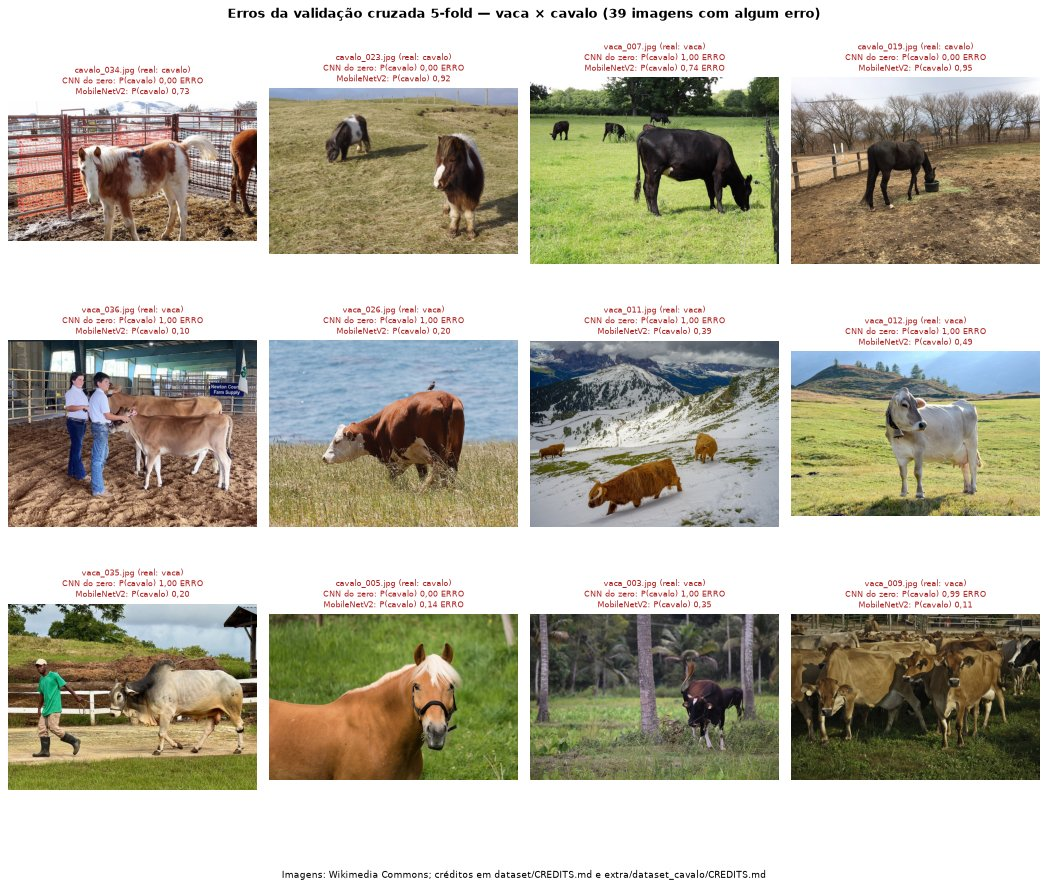

In [29]:
MAX_CV_ERRORS = 12


def cv_error_frame(pair: str) -> pd.DataFrame:
    rows = CV_PREDICTIONS[CV_PREDICTIONS["par"] == pair]
    wide = rows.pivot_table(index="arquivo", columns="modelo", values="prob_classe1")
    labels = rows.groupby("arquivo")["rotulo"].first()
    wrong = ((wide > DECISION_THRESHOLD).astype(int).ne(labels, axis=0))
    strength = (wide.sub(labels, axis=0).abs()).where(wrong).max(axis=1)
    return wide[wrong.any(axis=1)].assign(rotulo=labels, forca=strength).sort_values("forca", ascending=False)


def plot_cv_errors(pair: str, name: str) -> pd.DataFrame:
    errors = cv_error_frame(pair)
    if errors.empty:
        print("Nenhum erro na validação cruzada.")
        return errors
    second = classes_of(pair)[1]
    shown = errors.head(MAX_CV_ERRORS)
    fig, axes = gallery_axes(len(shown))
    for ax, (file, row) in zip(axes, shown.iterrows()):
        ax.imshow(Image.open(PATH_INDEX[pair][file]))
        lines = [f"{model_name.split(' (')[0]}: P({second}) {fmt_num(row[model_name], 2)}"
                 + (" ERRO" if int(row[model_name] > DECISION_THRESHOLD) != row["rotulo"] else "") for model_name in IR_TRAINERS]
        ax.set_title("\n".join([f"{file} (real: {classes_of(pair)[int(row['rotulo'])]})", *lines]), fontsize=7.5, color=ERROR_COLOR)
    fig.suptitle(f"Erros da validação cruzada 5-fold — {pair} ({len(errors)} imagens com algum erro)", fontweight="bold")
    fig.text(0.5, 0, CREDITS_CAPTION, ha="center", fontsize=8)
    fig.tight_layout(rect=(0, 0.03, 1, 1))
    save_photo_grid(fig, name)
    return errors


CV_ERRORS = plot_cv_errors(PAIR_NEW, "erros_validacao_cruzada.png")

### C.6 O atalho do fundo ainda funciona?

O teste da segunda parte da hipótese. Para cada imagem, pintamos de preto **o retângulo que envolve todas as caixas rotuladas** do objeto, deixando só o fundo, e perguntamos se um classificador ainda acerta a classe. É o mesmo princípio da imagem "só fundo" do Ir Além (lá o retângulo envolvia a máscara do SAM 2); aqui usamos as caixas verdadeiras, disponíveis para os dois pares, o que elimina erros de detecção e aplica **exatamente o mesmo procedimento** a vaca × trator e a vaca × cavalo. O tamanho e a posição do retângulo ainda vazam alguma informação, então a medida é um limite superior do poder do fundo.

Classificador: as 1280 características da MobileNetV2 ImageNet congelada (GAP), centradas pela média do treino e normalizadas, e uma regressão logística, avaliadas na mesma validação cruzada 5-fold (cada imagem prevista uma vez). Reportamos acurácia com Wilson, o teste binomial contra o acaso (50%, unilateral) e a fração média do quadro que sobra como fundo.

**Controle de vazamento:** a mesma regressão logística recebe **só a geometria do retângulo** (cantos normalizados, área e proporção, padronizados), sem nenhum pixel. Se ela acertar tanto quanto o "só fundo", o sinal medido pode vir do tamanho e da posição do animal no quadro, e não do cenário; o McNemar entre as duas variantes, nas mesmas 80 imagens, diz se o fundo acrescenta algo à geometria. A referência do Ir Além (sondagem com 32 imagens por classe, pesos ImageNet, "só fundo") é lida de `ir_alem/figuras/sondagem_k_shot.csv`.

In [30]:
PROBE_REGULARIZATION = 1.0
PROBE_MAX_ITER = 2000
VARIANT_ORIGINAL, VARIANT_BACKGROUND, VARIANT_GEOMETRY = "Original", "Só fundo", "Só a geometria do retângulo"
CHANCE = 0.5


def enclosing_box(pair: str, path: Path) -> tuple[int, int, int, int]:
    width, height = Image.open(path).size
    boxes = np.array([box for _, box in TRUTHS[pair][path.name]])
    scale = np.array([IR_IMG_SIZE / width, IR_IMG_SIZE / height] * 2)
    x0, y0 = np.floor(boxes[:, :2].min(axis=0) * scale[:2]).astype(int)
    x1, y1 = np.ceil(boxes[:, 2:].max(axis=0) * scale[2:]).astype(int)
    return max(x0, 0), max(y0, 0), min(x1, IR_IMG_SIZE), min(y1, IR_IMG_SIZE)


def background_only(pair: str) -> np.ndarray:
    images, _, paths = IR_POOLS[pair]
    covered = images.copy()
    for image, path in zip(covered, paths):
        x0, y0, x1, y1 = enclosing_box(pair, path)
        image[y0:y1, x0:x1] = 0
    return covered


def extract_features(base: keras.Model, x: np.ndarray) -> np.ndarray:
    batches = [base(mobilenet_v2.preprocess_input(x[start:start + IR_BATCH].copy()), training=False)
               for start in range(0, len(x), IR_BATCH)]
    return np.concatenate([batch.numpy().mean(axis=(1, 2)) for batch in batches])


def unit_rows(features: np.ndarray, center: np.ndarray) -> np.ndarray:
    centered = features - center
    return centered / np.linalg.norm(centered, axis=1, keepdims=True)


def standardized_rows(features: np.ndarray, center: np.ndarray, scale: np.ndarray) -> np.ndarray:
    return (features - center) / (scale + 1e-9)


def visible_fraction(images: np.ndarray) -> float:
    return float((images.sum(axis=-1) > 0).mean())


def geometry_features(pair: str) -> np.ndarray:
    boxes = np.array([enclosing_box(pair, path) for path in IR_POOLS[pair][2]], dtype=np.float32) / IR_IMG_SIZE
    widths, heights = boxes[:, 2] - boxes[:, 0], boxes[:, 3] - boxes[:, 1]
    return np.column_stack([boxes, widths * heights, widths / np.maximum(heights, 1e-3)])


def probe_transform(train_rows: np.ndarray, standardize: bool) -> Callable[[np.ndarray], np.ndarray]:
    center, scale = train_rows.mean(axis=0), train_rows.std(axis=0)
    if standardize:
        return lambda rows: standardized_rows(rows, center, scale)
    return lambda rows: unit_rows(rows, center)


def probe_predictions(features: np.ndarray, y: np.ndarray, standardize: bool) -> np.ndarray:
    predictions = np.zeros(len(y), dtype=int)
    for train, evaluation in StratifiedKFold(CV_FOLDS, shuffle=True, random_state=CV_SEED).split(features, y):
        transform = probe_transform(features[train], standardize)
        classifier = LogisticRegression(C=PROBE_REGULARIZATION, max_iter=PROBE_MAX_ITER)
        classifier.fit(transform(features[train]), y[train])
        predictions[evaluation] = classifier.predict(transform(features[evaluation]))
    return predictions


def probe_row(pair: str, variant: str, features: np.ndarray, visible: float) -> dict[str, Any]:
    y = IR_POOLS[pair][1].astype(int)
    PROBE_PREDICTIONS[(pair, variant)] = probe_predictions(features, y, standardize=variant == VARIANT_GEOMETRY)
    hits = int((PROBE_PREDICTIONS[(pair, variant)] == y).sum())
    return {"par": pair, "imagens": variant, "acertos": hits, "n": len(y), "acurácia": hits / len(y),
            CI_COLUMN: fmt_interval(*proportion_interval(hits, len(y))),
            "p (acima do acaso)": float(binomtest(hits, len(y), CHANCE, alternative="greater").pvalue),
            "fração do quadro visível": visible}


def probe_inputs(pair: str) -> list[tuple[str, np.ndarray, float]]:
    original, background = IR_POOLS[pair][0], BACKGROUND_IMAGES[pair]
    return [(VARIANT_ORIGINAL, extract_features(PROBE_BASE, original), visible_fraction(original)),
            (VARIANT_BACKGROUND, extract_features(PROBE_BASE, background), visible_fraction(background)),
            (VARIANT_GEOMETRY, geometry_features(pair), 0.0)]


def background_vs_geometry(pair: str) -> dict[str, Any]:
    truth = [str(label) for label in IR_POOLS[pair][1].astype(int)]
    background, geometry = ([str(label) for label in PROBE_PREDICTIONS[(pair, variant)]]
                            for variant in (VARIANT_BACKGROUND, VARIANT_GEOMETRY))
    only_background, only_geometry, p = mcnemar_exact(truth, background, geometry)
    return {"par": pair, "só o fundo acerta": only_background, "só a geometria acerta": only_geometry, "p (McNemar exato)": p}


def ir_alem_background_reference() -> float:
    probe = pd.read_csv(IR_ALEM_FIGURES / "sondagem_k_shot.csv")
    selected = probe[(probe["caracteristicas"] == "ImageNet") & (probe["imagens"] == VARIANT_BACKGROUND)]
    return float(selected[selected["k"] == selected["k"].max()]["acuracia"].mean())


keras.backend.clear_session()
PROBE_BASE = build_mobilenet_base()
BACKGROUND_IMAGES = {pair: background_only(pair) for pair in PAIRS}
PROBE_PREDICTIONS: dict[tuple[str, str], np.ndarray] = {}
PROBE_TABLE = pd.DataFrame([probe_row(pair, variant, features, visible) for pair in PAIRS
                            for variant, features, visible in probe_inputs(pair)]).set_index(["par", "imagens"])
BACKGROUND_GEOMETRY = pd.DataFrame([background_vs_geometry(pair) for pair in PAIRS]).set_index("par")
IR_ALEM_BACKGROUND = ir_alem_background_reference()
PROBE_TABLE.to_csv(FIGURES_DIR / "atalho_fundo.csv")
print(f"Referência do Ir Além (vaca × trator, só fundo, sondagem com o maior k): {fmt_pct(IR_ALEM_BACKGROUND)}")
display(PROBE_TABLE.style.format(precision=3, decimal=",", subset=["acurácia", "p (acima do acaso)", "fração do quadro visível"]))
BACKGROUND_GEOMETRY.style.format({"p (McNemar exato)": lambda value: fmt_num(value, 3)})

Referência do Ir Além (vaca × trator, só fundo, sondagem com o maior k): 76,4%


,só o fundo acerta,só a geometria acerta,p (McNemar exato)
par,,,
vaca × trator,18,7,"0,043"
vaca × cavalo,6,5,"1,000"


À esquerda, exemplos das imagens "só fundo" de vaca × cavalo (duas vacas e dois cavalos). À direita, a acurácia da sondagem por par (imagem original, só fundo e só a geometria do retângulo), com o intervalo de Wilson; a linha pontilhada é o acaso e o losango é a referência "só fundo" do Ir Além para vaca × trator.

Figura salva em extra/figuras/atalho_fundo.png (179 KB)


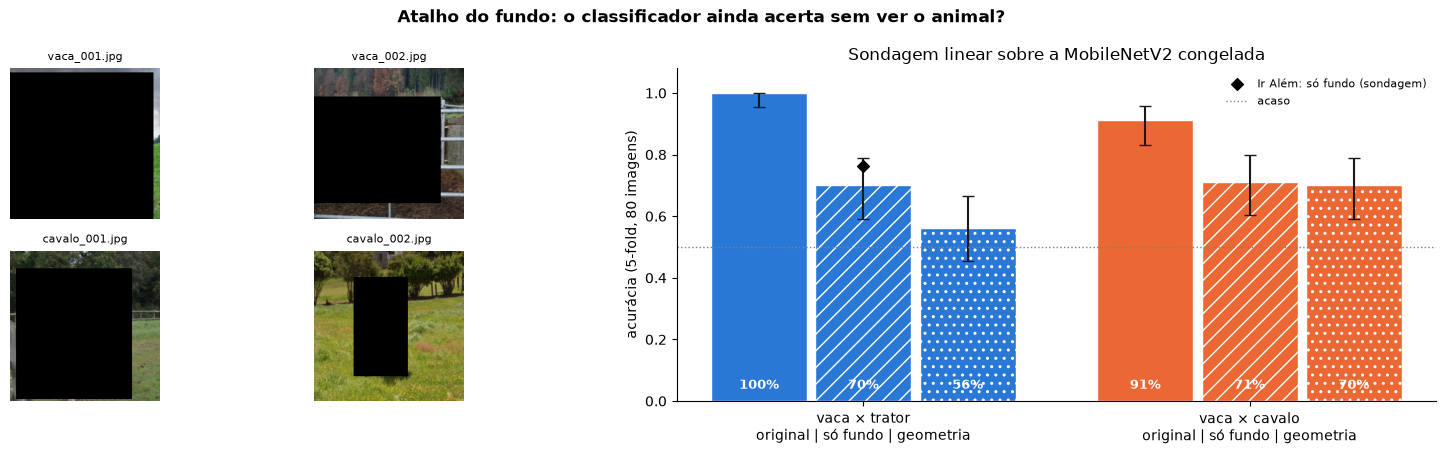

In [31]:
EXAMPLES_PER_CLASS = 2


def background_examples(pair: str) -> list[tuple[np.ndarray, str]]:
    _, y, paths = IR_POOLS[pair]
    picks = [index for label in (0, 1) for index in np.flatnonzero(y == label)[:EXAMPLES_PER_CLASS]]
    return [(BACKGROUND_IMAGES[pair][index], paths[index].name) for index in picks]


PROBE_STYLES = ((VARIANT_ORIGINAL, ""), (VARIANT_BACKGROUND, "//"), (VARIANT_GEOMETRY, ".."))


def draw_probe_bars(ax: plt.Axes) -> None:
    width = 0.27
    for offset, (variant, hatch) in zip((-width, 0.0, width), PROBE_STYLES):
        for position, pair in enumerate(PAIRS):
            row = PROBE_TABLE.loc[(pair, variant)]
            low, high = proportion_interval(int(row["acertos"]), int(row["n"]))
            ax.bar(position + offset, row["acurácia"], width * 0.92, color=PAIR_COLORS[pair], hatch=hatch, edgecolor="white",
                   yerr=[[row["acurácia"] - low], [high - row["acurácia"]]], capsize=4)
            ax.text(position + offset, 0.04, fmt_pct(row["acurácia"], 0), ha="center", color="white", fontweight="bold", fontsize=9)
    ax.scatter([list(PAIRS).index(PAIR_OLD)], [IR_ALEM_BACKGROUND], marker="D", color="black", zorder=3,
               label="Ir Além: só fundo (sondagem)")
    ax.axhline(CHANCE, color="gray", linestyle=":", linewidth=1, label="acaso")
    ax.set_xticks(range(len(PAIRS)), [f"{pair}\noriginal | só fundo | geometria" for pair in PAIRS])
    ax.set(ylim=(0, 1.08), ylabel="acurácia (5-fold, 80 imagens)", title="Sondagem linear sobre a MobileNetV2 congelada")
    ax.legend(frameon=False, fontsize=8, loc="upper right")
    ax.spines[["top", "right"]].set_visible(False)


def plot_shortcut(name: str) -> None:
    fig = plt.figure(figsize=(15, 4.6))
    grid = fig.add_gridspec(2, 4, width_ratios=[1, 1, 0.15, 3.2])
    for index, (image, file) in enumerate(background_examples(PAIR_NEW)):
        ax = fig.add_subplot(grid[index // 2, index % 2])
        ax.imshow(image.astype(np.uint8))
        ax.set_title(file, fontsize=8)
        ax.axis("off")
    draw_probe_bars(fig.add_subplot(grid[:, 3]))
    fig.suptitle("Atalho do fundo: o classificador ainda acerta sem ver o animal?", fontweight="bold")
    fig.tight_layout()
    save_chart(fig, name)


plot_shortcut("atalho_fundo.png")

---
## D. Lado a lado: vaca × trator × vaca × cavalo

### D.1 Tabela comparativa

Uma linha por métrica, com o mesmo modelo, a mesma receita e o mesmo protocolo nos dois pares, todas lidas das tabelas acima (nada digitado). Detecção = YOLO customizado `e60`; classificação por imagem em val+teste (16 imagens); validação cruzada nas 80 imagens; atalho = sondagem "só fundo". A coluna `diferença` é vaca × cavalo − vaca × trator. A tabela vai para `extra/figuras/comparacao_pares.csv`.

In [32]:
def yolo_metric(pair: str, metric: str, split: str = TEST_SET) -> float:
    return float(YOLO_METRICS.loc[(pair, split), metric])


def object_metric(pair: str, metric: str, approach: str = CUSTOM) -> float:
    return float(OBJECT_TABLE.loc[(pair, approach, VAL_TEST_SET), metric])


def image_accuracy(pair: str, approach: str) -> float:
    return float(IMAGE_TABLE.loc[(VAL_TEST_SET, pair, approach), "acurácia"])


def cv_metric(pair: str, model_name: str, metric: str = "acurácia") -> float:
    return float(CV_SUMMARY.loc[(pair, model_name), metric])


def probe_accuracy(pair: str, variant: str) -> float:
    return float(PROBE_TABLE.loc[(pair, variant), "acurácia"])


COMPARISON_SPEC = [
    ("Entrega 1 · detecção (teste)", "mAP50 do YOLO customizado", lambda pair: yolo_metric(pair, "mAP50"), True),
    ("Entrega 1 · detecção (teste)", "mAP50-95 do YOLO customizado", lambda pair: yolo_metric(pair, "mAP50-95"), True),
    ("Entrega 1 · detecção (teste)", "mAP50-95 da classe vaca", lambda pair: yolo_metric(pair, "mAP50-95 vaca"), True),
    ("Entrega 1 · objeto a objeto (val+teste)", "revocação (troca conta como erro)", lambda pair: object_metric(pair, "revocação"), True),
    ("Entrega 1 · objeto a objeto (val+teste)", "trocas de classe (YOLO customizado)", lambda pair: object_metric(pair, SWAP), False),
    ("Entrega 1 · objeto a objeto (val+teste)", "trocas de classe (YOLO do COCO)", lambda pair: object_metric(pair, SWAP, COCO), False),
    ("Entrega 2 · por imagem (val+teste)", f"acurácia {COCO}", lambda pair: image_accuracy(pair, COCO), True),
    ("Entrega 2 · por imagem (val+teste)", f"acurácia {CUSTOM}", lambda pair: image_accuracy(pair, CUSTOM), True),
    ("Entrega 2 · por imagem (val+teste)", f"acurácia {CNN_MEAN}", lambda pair: image_accuracy(pair, CNN_MEAN), True),
    ("Ir Além · CV 5-fold (80 imagens)", f"acurácia {MODEL_SCRATCH}", lambda pair: cv_metric(pair, MODEL_SCRATCH), True),
    ("Ir Além · CV 5-fold (80 imagens)", f"acurácia {MODEL_TRANSFER}", lambda pair: cv_metric(pair, MODEL_TRANSFER), True),
    ("Ir Além · CV 5-fold (80 imagens)", f"log-loss {MODEL_SCRATCH}", lambda pair: cv_metric(pair, MODEL_SCRATCH, "log-loss (média dos folds)"), False),
    ("Ir Além · CV 5-fold (80 imagens)", f"log-loss {MODEL_TRANSFER}", lambda pair: cv_metric(pair, MODEL_TRANSFER, "log-loss (média dos folds)"), False),
    ("Atalho do fundo (5-fold)", "acurácia com a imagem original", lambda pair: probe_accuracy(pair, VARIANT_ORIGINAL), True),
    ("Atalho do fundo (5-fold)", "acurácia só com o fundo", lambda pair: probe_accuracy(pair, VARIANT_BACKGROUND), True),
    ("Atalho do fundo (5-fold)", "acurácia só com a geometria do retângulo", lambda pair: probe_accuracy(pair, VARIANT_GEOMETRY), True),
]

COMPARISON = pd.DataFrame([{"etapa": stage, "métrica": metric, **{pair: getter(pair) for pair in PAIRS}, "maior é melhor": higher}
                           for stage, metric, getter, higher in COMPARISON_SPEC])
COMPARISON["diferença"] = COMPARISON[PAIR_NEW] - COMPARISON[PAIR_OLD]
COMPARISON.to_csv(FIGURES_DIR / "comparacao_pares.csv", index=False)
COMPARISON.set_index(["etapa", "métrica"]).drop(columns="maior é melhor").style.format(precision=3, decimal=",")

### D.2 Figura comparativa

As métricas em escala 0–1 da tabela anterior (contagens e log-loss ficam de fora), uma barra por par. Leitura: quanto mais a barra laranja (vaca × cavalo) fica abaixo da azul (vaca × trator), mais o par novo é difícil para aquela abordagem; na última linha, quanto mais perto do acaso, menos o fundo sozinho resolve o problema.

Figura salva em extra/figuras/comparacao_pares.png (83 KB)


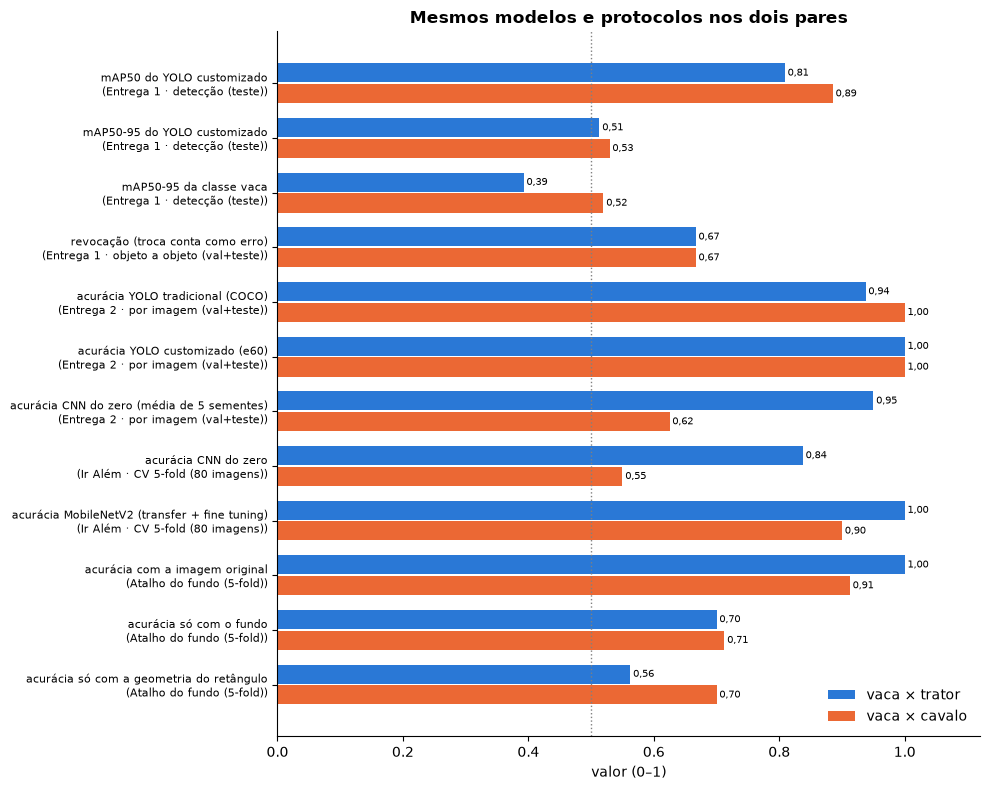

In [33]:
def plot_pair_comparison(name: str) -> None:
    bounded = COMPARISON[~COMPARISON["métrica"].str.startswith(("trocas", "log-loss"))].reset_index(drop=True)
    positions = np.arange(len(bounded))
    height = 0.38
    fig, ax = plt.subplots(figsize=(10, 0.55 * len(bounded) + 1.4))
    for offset, pair in zip((-height / 2, height / 2), PAIRS):
        bars = ax.barh(positions + offset, bounded[pair], height * 0.92, color=PAIR_COLORS[pair], label=pair)
        ax.bar_label(bars, labels=[fmt_num(value, 2) for value in bounded[pair]], fontsize=7.5, padding=2)
    ax.axvline(CHANCE, color="gray", linestyle=":", linewidth=1)
    ax.set_yticks(positions, [f"{metric}\n({stage})" for stage, metric in zip(bounded["etapa"], bounded["métrica"])], fontsize=8)
    ax.invert_yaxis()
    ax.set(xlim=(0, 1.12), xlabel="valor (0–1)")
    ax.legend(frameon=False, loc="lower right")
    ax.spines[["top", "right"]].set_visible(False)
    ax.set_title("Mesmos modelos e protocolos nos dois pares", fontweight="bold")
    fig.tight_layout()
    save_chart(fig, name)


plot_pair_comparison("comparacao_pares.png")

## Conclusões

### Conclusões numéricas (geradas a partir dos resultados)

A célula abaixo escreve as conclusões **a partir das tabelas desta execução**; se o notebook for reexecutado (por exemplo no Colab, com GPU para o TensorFlow, ou com mais imagens de cavalo), todos os números e vereditos se atualizam sozinhos. Critérios:

* **"A dificuldade sobe":** quantos dos indicadores pareados por modelo pioram de vaca × trator para vaca × cavalo (erros da CNN do zero e da MobileNetV2 na validação cruzada, mAP50-95 de teste do YOLO, trocas de classe, acurácia média da CNN da Entrega 2), com o teste de Fisher como prova estatística principal (a validação cruzada tem o maior suporte, 80 imagens).
* **"O atalho do fundo deixa de funcionar":** a sondagem "só fundo" de vaca × cavalo deixa de ficar significativamente acima do acaso (teste binomial unilateral, 5%), enquanto a de vaca × trator fica. Se as duas ficarem acima, o controle de geometria diz se o sinal vem do cenário ou do tamanho e da posição do animal.
* **Em quem confiar:** a abordagem com mais acertos em vaca × cavalo no maior conjunto em que ela foi avaliada, com o aviso de quando os intervalos não a separam das demais.

In [34]:
def errors_of(pair: str, model_name: str) -> int:
    return int(CV_SUMMARY.loc[(pair, model_name), "n"] - CV_SUMMARY.loc[(pair, model_name), "acertos"])


def change_word(old: float, new: float, higher_is_better: bool) -> str:
    if np.isclose(old, new):
        return "igual"
    return "piora" if (new < old) == higher_is_better else "melhora"


def difficulty_indicators() -> list[tuple[str, float, float, bool, int]]:
    return [
        (f"erros da {MODEL_SCRATCH} na CV", errors_of(PAIR_OLD, MODEL_SCRATCH), errors_of(PAIR_NEW, MODEL_SCRATCH), False, 0),
        ("erros da MobileNetV2 na CV", errors_of(PAIR_OLD, MODEL_TRANSFER), errors_of(PAIR_NEW, MODEL_TRANSFER), False, 0),
        ("mAP50-95 de teste do YOLO customizado", yolo_metric(PAIR_OLD, "mAP50-95"), yolo_metric(PAIR_NEW, "mAP50-95"), True, 3),
        ("trocas de classe do YOLO customizado (val+teste)", object_metric(PAIR_OLD, SWAP), object_metric(PAIR_NEW, SWAP), False, 0),
        (f"acurácia da {CNN_MEAN} (val+teste)", image_accuracy(PAIR_OLD, CNN_MEAN), image_accuracy(PAIR_NEW, CNN_MEAN), True, 3),
    ]


def indicator_text(name: str, old: float, new: float, higher: bool, digits: int) -> str:
    return f"{name}: {fmt_num(old, digits)} → {fmt_num(new, digits)} ({change_word(old, new, higher)})"


def difficulty_line() -> str:
    indicators = difficulty_indicators()
    worse = sum(change_word(old, new, higher) == "piora" for _, old, new, higher, _ in indicators)
    p = float(FISHER_TABLE.loc[MODEL_SCRATCH, "p (Fisher exato)"])
    significance = "significativa" if p < SIGNIFICANCE else "não significativa"
    majority = worse > len(indicators) / 2
    if majority and p < SIGNIFICANCE:
        verdict = (f"**confirmada**: a maioria dos indicadores piora e a diferença de erros da {MODEL_SCRATCH} na validação "
                   "cruzada é estatisticamente significativa")
    elif majority:
        verdict = "**confirmada só na direção**: a maioria dos indicadores piora, mas sem significância estatística (amostra pequena)"
    elif worse == 0:
        verdict = "**refutada** nesta amostra: nenhum indicador piora"
    else:
        verdict = "**inconclusiva**: os indicadores apontam em direções diferentes"
    details = "; ".join(indicator_text(*indicator) for indicator in indicators)
    return (f"**A dificuldade sobe?** {worse} de {len(indicators)} indicadores pioram em vaca × cavalo ({details}). "
            f"Fisher para a {MODEL_SCRATCH}: {fmt_p(p)}, diferença {significance}. Veredito: {verdict}")


def cow_line() -> str:
    parts = "; ".join(f"{model_name}: {FISHER_TABLE.loc[model_name, f'erros em vacas {PAIR_OLD}']} → "
                      f"{FISHER_TABLE.loc[model_name, f'erros em vacas {PAIR_NEW}']}" for model_name in IR_TRAINERS)
    return (f"**As mesmas vacas, outro vizinho:** erros da validação cruzada **nas 40 imagens de vaca**, que são idênticas nos dois "
            f"pares ({PAIR_OLD} → {PAIR_NEW}): {parts}. Qualquer aumento aqui vem só de a segunda classe ter ficado parecida")


def scenery_adds(pair: str) -> bool:
    test = BACKGROUND_GEOMETRY.loc[pair]
    return bool(test["p (McNemar exato)"] < SIGNIFICANCE and test["só o fundo acerta"] > test["só a geometria acerta"])


def geometry_reading(pair: str) -> str:
    geometry = PROBE_TABLE.loc[(pair, VARIANT_GEOMETRY)]
    test = BACKGROUND_GEOMETRY.loc[pair]
    head = (f"em {pair}, só a geometria do retângulo acerta {fmt_pct(geometry['acurácia'])} ({fmt_p(geometry['p (acima do acaso)'])} "
            f"contra o acaso); fundo × geometria: só o fundo acerta {int(test['só o fundo acerta'])} imagens, só a geometria "
            f"{int(test['só a geometria acerta'])} ({fmt_p(test['p (McNemar exato)'])})")
    if scenery_adds(pair):
        return f"{head}: o cenário acrescenta informação além do tamanho e da posição do animal"
    return f"{head}: o fundo não acrescenta nada mensurável à geometria do retângulo"


def background_verdict(old_p: float, new_p: float) -> str:
    old_works, new_works = old_p < SIGNIFICANCE, new_p < SIGNIFICANCE
    if old_works and not new_works:
        return "**confirmada**: em vaca × trator o fundo sozinho fica acima do acaso; em vaca × cavalo, não"
    if old_works and new_works:
        control = "Controle de vazamento: " + "; ".join(geometry_reading(pair) for pair in PAIRS)
        if scenery_adds(PAIR_OLD) and not scenery_adds(PAIR_NEW):
            return ("**confirmada quanto ao cenário**: o que sobra sem o animal ainda fica acima do acaso nos dois pares, mas em "
                    "vaca × cavalo esse sinal é explicado pelo enquadramento (tamanho e posição do retângulo, ou seja, como as fotos "
                    "foram tiradas), enquanto em vaca × trator o cenário em si carrega informação. " + control)
        if scenery_adds(PAIR_NEW):
            return ("**refutada**: em vaca × cavalo o cenário ainda carrega informação além do enquadramento, um viés de como as "
                    "fotos de cada classe foram escolhidas. " + control)
        return "**inconclusiva**: o fundo fica acima do acaso nos dois pares, mas não supera a geometria em nenhum. " + control
    if not old_works and not new_works:
        return "**inconclusiva**: nesta medida o fundo não fica acima do acaso em nenhum dos pares"
    return "**invertida**: o fundo só fica acima do acaso em vaca × cavalo"


def background_line() -> str:
    rows = {pair: PROBE_TABLE.loc[(pair, VARIANT_BACKGROUND)] for pair in PAIRS}
    listing = "; ".join(f"{pair}: {fmt_pct(row['acurácia'])} {row[CI_COLUMN]}, {fmt_p(row['p (acima do acaso)'])}, "
                        f"{fmt_pct(row['fração do quadro visível'], 0)} do quadro visível" for pair, row in rows.items())
    return (f"**O atalho do fundo deixa de funcionar?** Sondagem só com o fundo: {listing}. Referência do Ir Além para vaca × trator: "
            f"{fmt_pct(IR_ALEM_BACKGROUND)}. Veredito: {background_verdict(rows[PAIR_OLD]['p (acima do acaso)'], rows[PAIR_NEW]['p (acima do acaso)'])}")


def swap_line() -> str:
    old, new = (int(object_metric(pair, SWAP)) for pair in PAIRS)
    coco_new = int(object_metric(PAIR_NEW, SWAP, COCO))
    if new > old:
        head = f"a **troca de classe** aparece como modo de falha novo: {old} troca(s) em vaca × trator contra {new} em vaca × cavalo"
    else:
        head = f"a troca de classe não aumentou nesta amostra ({old} em vaca × trator, {new} em vaca × cavalo)"
    return (f"**Detecção:** {head} (YOLO customizado, val+teste); o YOLO do COCO, que nunca viu este dataset, faz "
            f"{plural(coco_new, 'troca', 'trocas')} em vaca × cavalo. Detalhe do YOLO customizado: "
            f"{swap_text(MATCHES[(PAIR_NEW, CUSTOM, VAL_TEST_SET)])}")


def trust_candidates() -> list[tuple[str, int, int, str]]:
    return [
        (f"{MODEL_TRANSFER} (CV)", int(CV_SUMMARY.loc[(PAIR_NEW, MODEL_TRANSFER), "acertos"]), int(CV_SUMMARY.loc[(PAIR_NEW, MODEL_TRANSFER), "n"]), "CV"),
        (f"{MODEL_SCRATCH} do Ir Além (CV)", int(CV_SUMMARY.loc[(PAIR_NEW, MODEL_SCRATCH), "acertos"]), int(CV_SUMMARY.loc[(PAIR_NEW, MODEL_SCRATCH), "n"]), "CV"),
        *[(f"{approach} (val+teste)", int(IMAGE_TABLE.loc[(VAL_TEST_SET, PAIR_NEW, approach), "acertos"]),
           int(IMAGE_TABLE.loc[(VAL_TEST_SET, PAIR_NEW, approach), "n"]), "val+teste") for approach in CLASSIFIERS],
    ]


def trust_line() -> str:
    candidates = trust_candidates()
    scored = [(name, hits / total, proportion_interval(hits, total), kind) for name, hits, total, kind in candidates]
    best = max(scored, key=lambda item: (item[1], item[3] == "CV"))
    overlapping = [name for name, _, (low, high), _ in scored if name != best[0] and high >= best[2][0]]
    listing = "; ".join(f"{name} {fmt_pct(accuracy)} {fmt_interval(*interval)}" for name, accuracy, interval, _ in scored)
    caveat = (f"Os intervalos de {', '.join(overlapping)} se sobrepõem ao dela: a ordem não é definitiva com esta amostra"
              if overlapping else "Nenhum intervalo das demais se sobrepõe ao dela")
    return f"**Em quem confiar em vaca × cavalo:** {listing}. Maior acurácia: **{best[0]}**. {caveat}"


def latency_line() -> str:
    cpu = TIMING_TABLE.xs("CPU", level="dispositivo")["mediana (ms/img)"]
    return ("**Custo:** mediana na CPU, do arquivo à predição: " + "; ".join(f"{name} {fmt_num(value, 1)} ms" for name, value in cpu.items())
            + ". A troca de par não muda a latência: as arquiteturas são as mesmas da Entrega 2")


def pretraining_line() -> str:
    gaps = {pair: errors_of(pair, MODEL_SCRATCH) - errors_of(pair, MODEL_TRANSFER) for pair in PAIRS}
    counts = "; ".join(f"{pair}: MobileNetV2 {errors_of(pair, MODEL_TRANSFER)} × CNN do zero {errors_of(pair, MODEL_SCRATCH)} erros em 80"
                       for pair in PAIRS)
    if gaps[PAIR_NEW] <= 0:
        return f"**Para a FarmTech:** nesta amostra o pré-treino não reduziu os erros em vaca × cavalo ({counts}); a escolha deve ser revista com mais dados"
    growth = ("e a vantagem do pré-treino cresce quando as classes ficam parecidas" if gaps[PAIR_NEW] > gaps[PAIR_OLD]
              else "com vantagem do pré-treino semelhante ou menor que a do par fácil")
    return (f"**Para a FarmTech:** o modelo pré-treinado erra menos que a CNN do zero em vaca × cavalo ({counts}), {growth}. "
            "Para rebanho misto, a base do produto deve ser uma rede pré-treinada, não uma CNN pequena treinada do zero")


def coco_line() -> str:
    coco_accuracy, custom_accuracy = image_accuracy(PAIR_NEW, COCO), image_accuracy(PAIR_NEW, CUSTOM)
    comparison = f"({fmt_pct(custom_accuracy)} × {fmt_pct(coco_accuracy)} por imagem em val+teste)"
    head = "Como `cow` e `horse` existem no COCO, o YOLO pré-treinado é um concorrente real sem custo de anotação"
    if custom_accuracy > coco_accuracy:
        return f"{head}, e mesmo assim o customizado o supera {comparison}: treinar com fotos do próprio problema compensa"
    relation = "empata com o" if np.isclose(custom_accuracy, coco_accuracy) else "fica abaixo do"
    return (f"{head}: o customizado {relation} COCO {comparison}. Customizar só se justifica onde o COCO não chega "
            "(classes fora do vocabulário, como `trator`, ou câmeras e raças específicas do cliente)")


def species_error_line() -> str:
    swaps = int(object_metric(PAIR_NEW, SWAP)) + int(object_metric(PAIR_NEW, SWAP, COCO))
    cow_increase = any(FISHER_TABLE.loc[model_name, f"erros em vacas {PAIR_NEW}"] > FISHER_TABLE.loc[model_name, f"erros em vacas {PAIR_OLD}"]
                       for model_name in IR_TRAINERS)
    if swaps or cow_increase:
        return ("Num rebanho misto, o erro caro deixa de ser só 'não ver o animal' e passa a incluir **contar o animal na espécie errada**: "
                "o relatório ao cliente deve trazer a troca de classe como métrica própria, separada de objetos perdidos e alarmes falsos")
    return ("Nesta amostra a troca de espécie não apareceu nem na detecção nem nas vacas da validação cruzada; ainda assim, num produto "
            "para rebanho misto a troca de classe deve ser monitorada como métrica própria")


def farmtech_lines() -> list[str]:
    return [pretraining_line(), coco_line(), species_error_line()]


def detector_classifier_line() -> str:
    detector = {pair: min(image_accuracy(pair, approach) for approach in YOLO_APPROACHES) for pair in PAIRS}
    scratch = {pair: cv_metric(pair, MODEL_SCRATCH) for pair in PAIRS}
    swaps = int(object_metric(PAIR_NEW, SWAP)) + int(object_metric(PAIR_NEW, SWAP, COCO))
    detail = (f"pior YOLO por imagem em val+teste {fmt_pct(detector[PAIR_OLD])} → {fmt_pct(detector[PAIR_NEW])}; "
              f"{MODEL_SCRATCH} na CV {fmt_pct(scratch[PAIR_OLD])} → {fmt_pct(scratch[PAIR_NEW])}")
    if detector[PAIR_NEW] >= detector[PAIR_OLD] and scratch[PAIR_NEW] < scratch[PAIR_OLD] and swaps == 0:
        return (f"**Quem sente a dificuldade:** os classificadores pequenos, não os detectores ({detail}; nenhuma troca de classe "
                "nos dois YOLO). Os YOLO partem de pesos do COCO, que já separam `cow` de `horse`; a CNN do zero precisa aprender "
                "essa diferença fina com 64 fotos")
    return f"**Quem sente a dificuldade:** {detail}; trocas de classe dos dois YOLO em vaca × cavalo: {swaps}"


CONCLUSION_LINES = [difficulty_line(), detector_classifier_line(), cow_line(), background_line(), swap_line(), trust_line(),
                    latency_line(), *farmtech_lines()]
show_markdown(CONCLUSION_LINES, "Conclusões — vaca × cavalo")

#### Conclusões — vaca × cavalo
- **A dificuldade sobe?** 3 de 5 indicadores pioram em vaca × cavalo (erros da CNN do zero na CV: 13 → 36 (piora); erros da MobileNetV2 na CV: 0 → 8 (piora); mAP50-95 de teste do YOLO customizado: 0,513 → 0,529 (melhora); trocas de classe do YOLO customizado (val+teste): 0 → 0 (igual); acurácia da CNN do zero (média de 5 sementes) (val+teste): 0,950 → 0,625 (piora)). Fisher para a CNN do zero: p < 0,001, diferença significativa. Veredito: **confirmada**: a maioria dos indicadores piora e a diferença de erros da CNN do zero na validação cruzada é estatisticamente significativa
- **Quem sente a dificuldade:** os classificadores pequenos, não os detectores (pior YOLO por imagem em val+teste 93,8% → 100,0%; CNN do zero na CV 83,8% → 55,0%; nenhuma troca de classe nos dois YOLO). Os YOLO partem de pesos do COCO, que já separam `cow` de `horse`; a CNN do zero precisa aprender essa diferença fina com 64 fotos
- **As mesmas vacas, outro vizinho:** erros da validação cruzada **nas 40 imagens de vaca**, que são idênticas nos dois pares (vaca × trator → vaca × cavalo): CNN do zero: 10 → 20; MobileNetV2 (transfer + fine tuning): 0 → 3. Qualquer aumento aqui vem só de a segunda classe ter ficado parecida
- **O atalho do fundo deixa de funcionar?** Sondagem só com o fundo: vaca × trator: 70,0% [0,59; 0,79], p < 0,001, 40% do quadro visível; vaca × cavalo: 71,2% [0,61; 0,80], p < 0,001, 55% do quadro visível. Referência do Ir Além para vaca × trator: 76,4%. Veredito: **confirmada quanto ao cenário**: o que sobra sem o animal ainda fica acima do acaso nos dois pares, mas em vaca × cavalo esse sinal é explicado pelo enquadramento (tamanho e posição do retângulo, ou seja, como as fotos foram tiradas), enquanto em vaca × trator o cenário em si carrega informação. Controle de vazamento: em vaca × trator, só a geometria do retângulo acerta 56,2% (p = 0,157 contra o acaso); fundo × geometria: só o fundo acerta 18 imagens, só a geometria 7 (p = 0,043): o cenário acrescenta informação além do tamanho e da posição do animal; em vaca × cavalo, só a geometria do retângulo acerta 70,0% (p < 0,001 contra o acaso); fundo × geometria: só o fundo acerta 6 imagens, só a geometria 5 (p = 1,000): o fundo não acrescenta nada mensurável à geometria do retângulo
- **Detecção:** a troca de classe não aumentou nesta amostra (0 em vaca × trator, 0 em vaca × cavalo) (YOLO customizado, val+teste); o YOLO do COCO, que nunca viu este dataset, faz 0 trocas em vaca × cavalo. Detalhe do YOLO customizado: nenhuma troca de classe
- **Em quem confiar em vaca × cavalo:** MobileNetV2 (transfer + fine tuning) (CV) 90,0% [0,81; 0,95]; CNN do zero do Ir Além (CV) 55,0% [0,44; 0,65]; YOLO tradicional (COCO) (val+teste) 100,0% [0,81; 1,00]; YOLO customizado (e60) (val+teste) 100,0% [0,81; 1,00]; CNN do zero (semente 42) (val+teste) 62,5% [0,39; 0,82]. Maior acurácia: **YOLO tradicional (COCO) (val+teste)**. Os intervalos de MobileNetV2 (transfer + fine tuning) (CV), YOLO customizado (e60) (val+teste), CNN do zero (semente 42) (val+teste) se sobrepõem ao dela: a ordem não é definitiva com esta amostra
- **Custo:** mediana na CPU, do arquivo à predição: YOLO customizado (e60) 58,2 ms; YOLO tradicional (COCO) 62,4 ms; CNN do zero (semente 42) 28,7 ms. A troca de par não muda a latência: as arquiteturas são as mesmas da Entrega 2
- **Para a FarmTech:** o modelo pré-treinado erra menos que a CNN do zero em vaca × cavalo (vaca × trator: MobileNetV2 0 × CNN do zero 13 erros em 80; vaca × cavalo: MobileNetV2 8 × CNN do zero 36 erros em 80), e a vantagem do pré-treino cresce quando as classes ficam parecidas. Para rebanho misto, a base do produto deve ser uma rede pré-treinada, não uma CNN pequena treinada do zero
- Como `cow` e `horse` existem no COCO, o YOLO pré-treinado é um concorrente real sem custo de anotação: o customizado empata com o COCO (100,0% × 100,0% por imagem em val+teste). Customizar só se justifica onde o COCO não chega (classes fora do vocabulário, como `trator`, ou câmeras e raças específicas do cliente)
- Num rebanho misto, o erro caro deixa de ser só 'não ver o animal' e passa a incluir **contar o animal na espécie errada**: o relatório ao cliente deve trazer a troca de classe como métrica própria, separada de objetos perdidos e alarmes falsos

### Limitações

* **Amostra pequena:** 40 imagens por classe. Em val+teste cada imagem vale 6,25 pontos percentuais, e mesmo a validação cruzada (80 imagens) só detecta diferenças grandes; os intervalos de confiança das tabelas mostram o tamanho dessa incerteza.
* **Um único treino do YOLO por par:** a receita e a semente são as da Entrega 1, mas não repetimos o treino com outras sementes; diferenças pequenas de mAP entre os pares podem ser ruído de treino.
* **Pares parcialmente pareados:** as vacas são as mesmas nos dois pares, o que torna a comparação justa para elas, mas a segunda classe é outro conjunto de fotos. Parte da diferença pode vir de como as fotos de cavalo foram tiradas (enquadramento, distância, número de animais), não só da semelhança entre as espécies.
* **Medida do atalho do fundo:** o retângulo preto esconde o animal, mas seu tamanho e posição ainda vazam informação, e em fotos com o animal ocupando quase todo o quadro sobra pouco fundo para medir. O resultado é um limite superior do poder do fundo; por isso o controle só com a geometria do retângulo e a fração visível do quadro são reportados ao lado.
* **Domínio:** fotos públicas do Wikimedia Commons, de dia e com o animal em destaque. Câmeras fixas de fazenda, drones, visão noturna, potros, bezerros e rebanhos muito densos não foram avaliados.
* **Hardware:** localmente o TensorFlow roda na CPU (Windows nativo, sem GPU para o TensorFlow), então os tempos de treino das CNNs não são comparáveis aos do YOLO, que treina na GPU.

*Imagens: Wikimedia Commons, sob licenças abertas; créditos das vacas em `dataset/CREDITS.md` e dos cavalos em `extra/dataset_cavalo/CREDITS.md`.*